In [1]:
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow
import numpy as np
import math

from scipy import signal
import matplotlib.pyplot as plt
import matplotlib.ticker as ptick
from matplotlib.ticker import FixedLocator
from matplotlib.colors import LinearSegmentedColormap

from CSField import CSField
import JupiterMag as jm

jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

UC = UniversalColor()
UC.set_palette()

Importing Library
done


In [2]:
def day2hhmm(decimal_day):
    doy = int(decimal_day)
    rest = decimal_day - doy

    hours = int(rest*24)
    minutes = (rest*24-hours)*60

    if round(minutes) >= 60:
        hours += 1
        minutes = 0
    else:
        minutes = round(minutes)
    return hours, minutes


def hhmm2day(hours, minutes, seconds=0):
    fraction_of_day = hours/24 + minutes/(60*24) + seconds/(60*60*24)
    return fraction_of_day


def fmt_hhmm(decimal_day):
    hours, minutes = day2hhmm(decimal_day)
    hh = '{:02}'.format(hours)
    mm = '{:02}'.format(minutes)
    return hh+':'+mm

In [3]:
# Data from Connerney+2020: PJ index
con20_pj_idx = np.array([1, 3, 4, 5, 6,
                        7, 8, 9, 10, 11,
                        12, 13, 14, 15, 16,
                        17, 18, 19, 20, 21,
                        22, 23, 24], dtype=int)

# Data from Connerney+2020: Current constant [nT]
con20_mu_i_tot = np.array([150.1, 137.8, 127.2, 129.1, 130.1,
                           142.3, 140.1, 143.8, 137.0, 141.4,
                           124.2, 148.9, 145.3, 144.8, 149.9,
                           132.1, 133.5, 152.9, 138.5, 138.8,
                           156.1, 141.4, 146.3])

# Data from Connerney+2020: Radial current constant [MA]
con20_mu_i_rho = np.array([35.2, 14.6, 7.7, 11.5, 20.8,
                           20.2, 12.2, 21.1, 20.9, 10.7,
                           26.26, 16.4, 12.0, 19.6, 12.0,
                           13.6, 20.0, 12.8, 16.0, 17.3,
                           9.9, 16.1, 10.3])

In [4]:
# 定数
RJ = 71492*1E+3  # Jupiter radius [m]
RE = 1560*1E+3   # Europa radius [m]
# Angular velocity of Jupiter System III rotation [rad sec-1]
OMG_J = 2*np.pi/(9.55*3600)
OMG_G = 2*np.pi/(7.2*24*3600)   # Ganymede orbital angular velosity [rad/sec]

Psyn_eu = (11.22)*3600      # Moon's synodic period [sec]
Psyn_ga = (10.53)*3600      # Moon's synodic period [sec]

In [5]:
PJ_list = [1, 3, 4, 5,
           6, 7, 8, 9, 10,
           11, 12, 13, 14, 15,
           16, 17, 18, 19, 20,
           21, 22, 23, 24, 25,
           26, 27, 28, 29, 30,
           31, 32, 33, 34, 35,
           36, 37, 38, 39, 40,
           41, 42, 43, 44, 45,
           46, 47, 48, 49, 50,
           51, 52, 53, 54, 55,
           56, 57, 58, 59, 60,
           61, 62, 63, 64, 65,
           66, 67, 68, 69, 70,
           71, 72, 73, 74, 75,
           76, 77, 78, 79, 80]
dir = 'results/insitu_fit_a0_a1_b1_36rj'
f0 = np.loadtxt(dir+'/result_PJ' +
                str(PJ_list[0]).zfill(2)+'_PJ'+str(PJ_list[-1]).zfill(2)+'.txt')

# PJ6のデータを読み込む

In [6]:
PJ_num = 6
date_list = ['2017DOY136', '2017DOY137', '2017DOY138',
             '2017DOY139', '2017DOY140', '2017DOY141',]

dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
time_arr = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
JunoMLT = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

rx_pc *= 1/71492.0  # [RJ]
ry_pc *= 1/71492.0  # [RJ]
rz_pc *= 1/71492.0  # [RJ]

In [7]:
# 座標
r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
cos_phi = rx_pc/r_pc
sin_phi = ry_pc/r_pc
cos_theta = rz_pc/r_pc
sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
print('Distance [RJ]:', r_pc[0], r_pc[-1])

# ==============
# Internal field
Bx0_pc = np.zeros(time_arr.size)
By0_pc = np.zeros(time_arr.size)
Bz0_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                        ry_pc[i],
                                                        rz_pc[i])  # [nT]
dBx = Bx_pc - Bx0_pc
dBy = By_pc - By0_pc
dBz = Bz_pc - Bz0_pc
dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
dBphi = -dBx*sin_phi + dBy*cos_phi

# ======================
# Con2020 original value
jm.Con2020.Config(
    mu_i=con20_mu_i_tot[np.where(con20_pj_idx == 6)],
    i_rho=con20_mu_i_rho[np.where(con20_pj_idx == 6)],
)
dBx1_pc = np.zeros(time_arr.size)
dBy1_pc = np.zeros(time_arr.size)
dBz1_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    dBx1_pc[i], dBy1_pc[i], dBz1_pc[i] = jm.Con2020.Field(rx_pc[i],
                                                          ry_pc[i],
                                                          rz_pc[i])  # [nT]
dBr1_pc = dBx1_pc*sin_theta*cos_phi + dBy1_pc * \
    sin_theta*sin_phi + dBz1_pc*cos_theta
dBtheta1_pc = dBx1_pc*cos_theta*cos_phi + \
    dBy1_pc*cos_theta*sin_phi - dBz1_pc*sin_theta
dBphi1_pc = -dBx1_pc*sin_phi + dBy1_pc*cos_phi

Distance [RJ]: 44.09285625971904 39.84420692636267


In [8]:
# =========
# DoE model
csfield = CSField()

select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
print(f0[select_pj, 1], f0[select_pj, 3])

dBx2_pc = np.zeros(time_arr.size)
dBy2_pc = np.zeros(time_arr.size)
dBz2_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    csfield.config(
        i_phi0=f0[select_pj, 1],
        I_rho0=f0[select_pj, 3],
        a0=3.59746838E-6,
        MLT0=1.22795601,
        a1=-5.15316425,
        MLT1=-40.94971659,
        b1=3.64,
    )
    dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field(rx_pc[i],
                                                                ry_pc[i],
                                                                rz_pc[i],
                                                                JunoMLT[i])  # [T]

x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
dBx2_pc *= 1E+9    # [nT]
dBy2_pc *= 1E+9    # [nT]
dBz2_pc *= 1E+9    # [nT]
dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
    sin_theta*sin_phi + dBz2_pc*cos_theta
dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
    dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

4.698989898989899e-05 8.449286687704634


In [9]:
# ===========================================================
# RMSE（Root Mean Squared Error）
# ===========================================================
x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
in_30rj = np.where(r_pc < 36.0)[0][0]
out_30rj = np.where(r_pc < 36.0)[0][-1]
if PJ_num in [17]:
    in_5rj = np.where(rho_cs < 8.0)[0][0]
    out_5rj = np.where(rho_cs < 8.0)[0][-1]
else:
    in_5rj = np.where(rho_cs < 5.0)[0][0]
    out_5rj = np.where(rho_cs < 5.0)[0][-1]
in_num = in_5rj-in_30rj-1
out_num = out_30rj-out_5rj-1

# ===========================================================
# Sys3 (x, y, z) -> CS (rho, phi, z)
# ===========================================================
dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr2_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta2_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi2_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr2_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta2_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi2_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (FASTER):', RMS_total)

RMS total (FASTER): 2.7868247235602244


In [10]:
# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr1_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta1_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi1_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr1_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta1_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi1_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (Con2020):', RMS_total)

RMS total (Con2020): 2.9336969564063686


In [11]:
if PJ_num in [17]:
    r_ticks_ref = np.arange(8.0, 36.0+1, 1)
else:
    r_ticks_ref = np.arange(5.0, 36.0+1, 1)
r_ticks = np.zeros((r_ticks_ref.size*2, 2))
for i in range(r_ticks_ref.size):
    r_i = r_ticks_ref[-1]-i
    time_i = time_arr[np.where(r_pc < r_i)[0][0]]
    r_ticks[i, 0] = r_i
    r_ticks[i, 1] = time_i

    time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
    r_ticks[-i-1, 0] = r_i
    r_ticks[-i-1, 1] = time_i

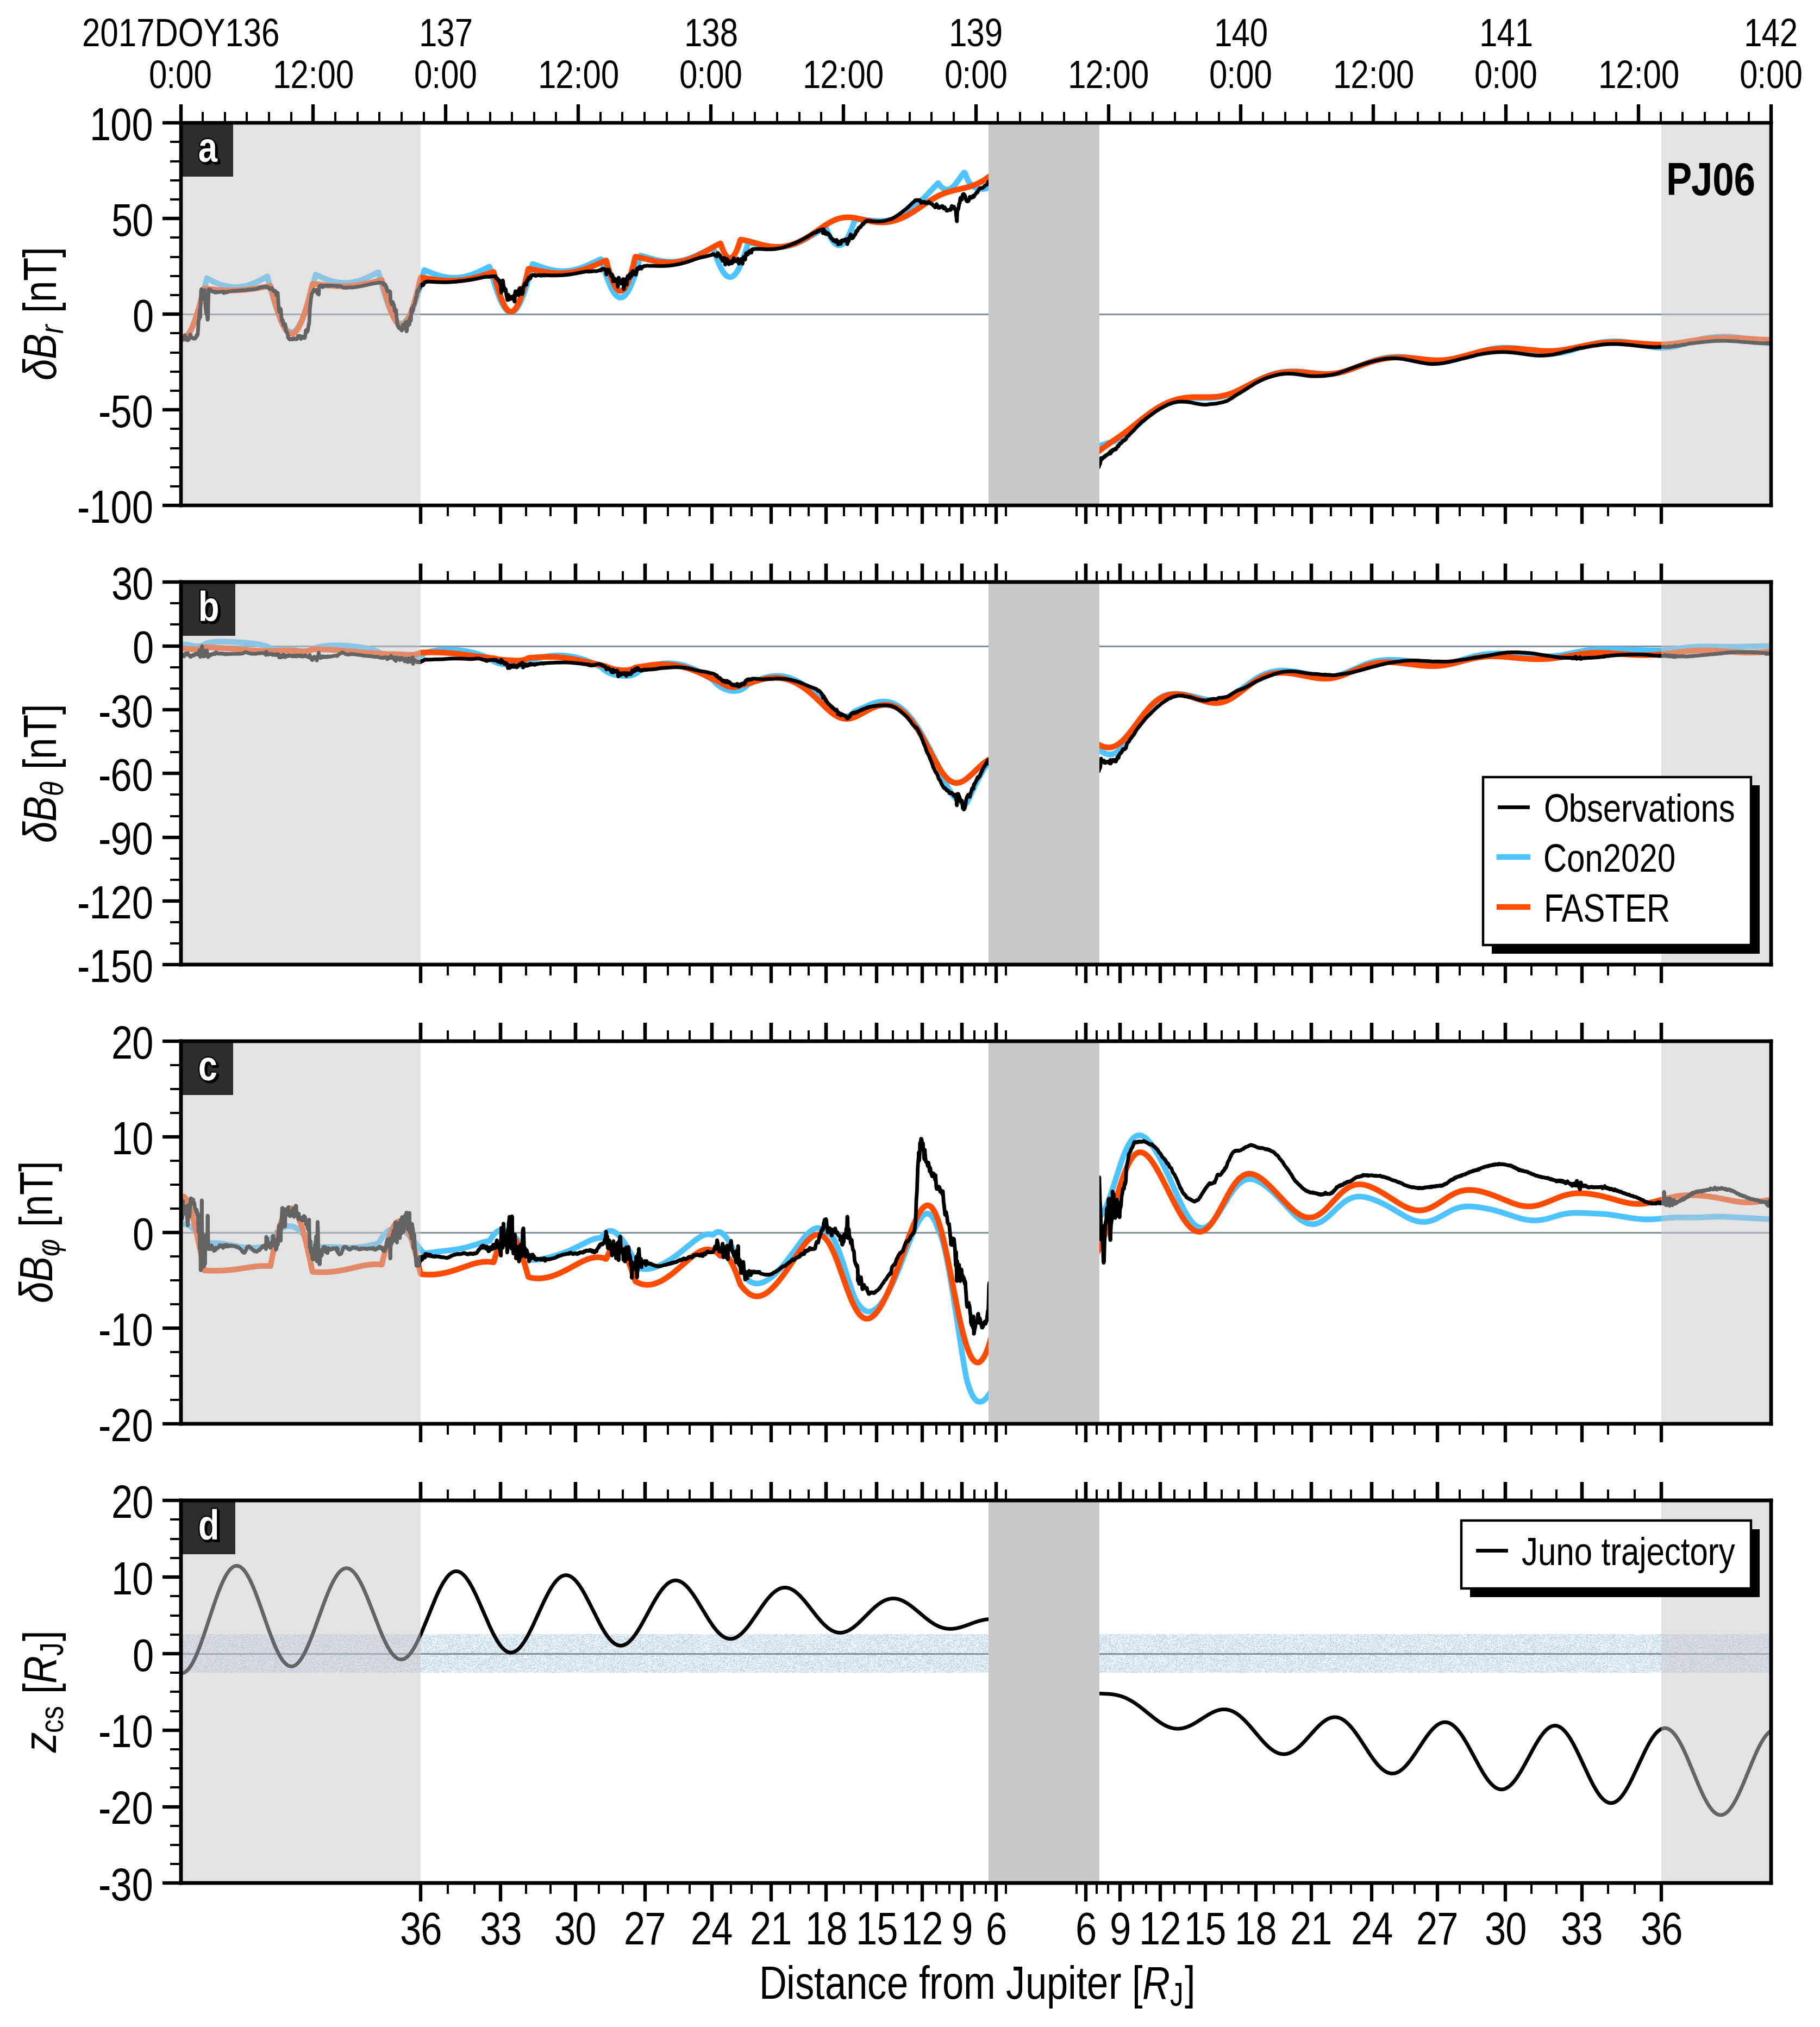

In [ ]:
F = ShareXaxis()
F.fontsize = 19
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=4, figsize=(10.0, 11.0), dpi='XL')
F.hspace = 0.2
F.initialize()

xticks = r_ticks[::3, 1]
xticklabels = r_ticks[::3, 0].astype(int)

F.set_xaxis(label=r'Distance from Jupiter [$R_{\rm J}$]',
            min=int(time_arr[0]),
            max=int(time_arr[-1])+1,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=None)
for i in range(4):
    F.ax[i].xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
for i in range(3):
    i += 1
    ax_upper = F.ax[i].twiny()
    ax_upper.set_xlim(int(time_arr[0]), int(time_arr[-1])+1)
    ax_upper.set_xticks(xticks)
    ax_upper.xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
    ax_upper.tick_params(labeltop=False)

F.set_yaxis(ax_idx=0,
            label=r'$\delta B_{r}$ [nT]',
            min=-100, max=100,
            ticks=np.linspace(-100, 100, 5),
            ticklabels=np.linspace(-100, 100, 5, dtype=int),
            minor_num=5)
F.set_yaxis(ax_idx=1,
            label=r'$\delta B_{\theta}$ [nT]',
            min=-150, max=30,
            ticks=np.linspace(-150, 30, 7),
            ticklabels=np.linspace(-150, 30, 7, dtype=int),
            minor_num=3)
F.set_yaxis(ax_idx=2,
            label=r'$\delta B_{\varphi}$ [nT]',
            min=-20, max=20,
            ticks=np.linspace(-20, 20, 5),
            ticklabels=np.linspace(-20, 20, 5, dtype=int),
            minor_num=4)
F.set_yaxis(ax_idx=3,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-30, max=20,
            ticks=np.linspace(-30, 20, 6),
            ticklabels=np.linspace(-30, 20, 6, dtype=int),
            minor_num=4)
F.ax[0].plot(time_arr, dBr, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[0].plot(time_arr, dBr1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[0].plot(time_arr, dBr2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[1].plot(time_arr, dBtheta1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[2].plot(time_arr, dBphi, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[2].plot(time_arr, dBphi1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[2].plot(time_arr, dBphi2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[3].plot(time_arr, z_cs, color='k',
             linewidth=1.5, label='Juno trajectory', zorder=1.0)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap="Blues",
    alpha=0.25,
    interpolation="nearest",
    aspect="auto",
)

"""# カラーマップと中心色
cmap = plt.get_cmap("Blues")
base_color = cmap(0.7)

# 正規分布に従う粒状ノイズ
rng = np.random.default_rng(42)
noise = rng.normal(loc=0.5, scale=0.35, size=(500, 1200))
noise = np.clip(noise, 0, 1)

im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap=cmap,
    vmin=0,
    vmax=1,
    alpha=0.25,
    interpolation="nearest",
    aspect="auto",
    zorder=2,
)"""

# Shades near Jupiter (< 5.0 RJ)
inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[inner_idx[0]],
                    time_arr[inner_idx[-1]],
                    fc=UC.lightgray, ec=None, zorder=2.5)

# Shades in the outer region
outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[0],
                    time_arr[outer_idx[0]],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)
    F.ax[i].axvspan(time_arr[outer_idx[-1]],
                    time_arr[-1],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)

# y = 0 line
for i in range(F.nrows):
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=0.9)

# Time axis
timeax = F.ax[0].twiny()
timeax.set_xlim(136, 142)
timeax.set_xticks([136.0, 136.5, 137.0, 137.5, 138.0, 138.5,
                   139.0, 139.5, 140.0, 140.5,
                   141.0, 141.5, 142.0])
timeax.set_xticklabels([date_list[0]+'\n0:00', '12:00',
                        '137\n0:00', '12:00',
                        '138\n0:00', '12:00', '139\n0:00', '12:00',
                        '140\n0:00', '12:00', '141\n0:00', '12:00',
                        '142\n0:00'], fontsize=F.fontsize*0.85)
timeax.xaxis.set_minor_locator(ptick.AutoMinorLocator(6))

F.ax[0].text(0.99, 0.9, 'PJ'+str(PJ_num).zfill(2),
             color='k',
             fontweight='bold',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)

legend = F.legend(ax_idx=1,
                  ncol=1, markerscale=1.0,
                  loc='lower right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)
legend = F.legend(ax_idx=3,
                  ncol=1, markerscale=1.0,
                  loc='upper right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[3], d=0.7)

plt.savefig('img/compare_a0_a1_b1_36rj/PJ'+str(PJ_num).zfill(2)+'.pdf',
            bbox_inches='tight')

# PJ4のデータを読み込む

In [13]:
PJ_num = 4
date_list = ['2017DOY031', '2017DOY032', '2017DOY033',
             '2017DOY034', '2017DOY035',]

dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
time_arr = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
JunoMLT = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

rx_pc *= 1/71492.0  # [RJ]
ry_pc *= 1/71492.0  # [RJ]
rz_pc *= 1/71492.0  # [RJ]

In [14]:
# 座標
r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
cos_phi = rx_pc/r_pc
sin_phi = ry_pc/r_pc
cos_theta = rz_pc/r_pc
sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
print('Distance [RJ]:', r_pc[0], r_pc[-1])

# ==============
# Internal field
Bx0_pc = np.zeros(time_arr.size)
By0_pc = np.zeros(time_arr.size)
Bz0_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                        ry_pc[i],
                                                        rz_pc[i])  # [nT]
dBx = Bx_pc - Bx0_pc
dBy = By_pc - By0_pc
dBz = Bz_pc - Bz0_pc
dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
dBphi = -dBx*sin_phi + dBy*cos_phi

# ======================
# Con2020 original value
jm.Con2020.Config(
    mu_i=con20_mu_i_tot[np.where(con20_pj_idx == PJ_num)],
    i_rho=con20_mu_i_rho[np.where(con20_pj_idx == PJ_num)],
)
dBx1_pc = np.zeros(time_arr.size)
dBy1_pc = np.zeros(time_arr.size)
dBz1_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    dBx1_pc[i], dBy1_pc[i], dBz1_pc[i] = jm.Con2020.Field(rx_pc[i],
                                                          ry_pc[i],
                                                          rz_pc[i])  # [nT]
dBr1_pc = dBx1_pc*sin_theta*cos_phi + dBy1_pc * \
    sin_theta*sin_phi + dBz1_pc*cos_theta
dBtheta1_pc = dBx1_pc*cos_theta*cos_phi + \
    dBy1_pc*cos_theta*sin_phi - dBz1_pc*sin_theta
dBphi1_pc = -dBx1_pc*sin_phi + dBy1_pc*cos_phi

Distance [RJ]: 37.83506258966213 37.16350624877827


In [15]:
# =========
# DoE model
csfield = CSField()

select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
print(f0[select_pj, 1], f0[select_pj, 3])

dBx2_pc = np.zeros(time_arr.size)
dBy2_pc = np.zeros(time_arr.size)
dBz2_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    csfield.config(
        i_phi0=f0[select_pj, 1],
        I_rho0=f0[select_pj, 3],
        a0=3.59746838E-6,
        MLT0=1.22795601,
        a1=-5.15316425,
        MLT1=-40.94971659,
        b1=3.64,
    )
    dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field(rx_pc[i],
                                                                ry_pc[i],
                                                                rz_pc[i],
                                                                JunoMLT[i])  # [T]

x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
dBx2_pc *= 1E+9    # [nT]
dBy2_pc *= 1E+9    # [nT]
dBz2_pc *= 1E+9    # [nT]
dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
    sin_theta*sin_phi + dBz2_pc*cos_theta
dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
    dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

4.6292929292929294e-05 -3.9561942655316984


In [16]:
# ===========================================================
# RMSE（Root Mean Squared Error）
# ===========================================================
x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
in_30rj = np.where(r_pc < 36.0)[0][0]
out_30rj = np.where(r_pc < 36.0)[0][-1]
if PJ_num in [17]:
    in_5rj = np.where(rho_cs < 8.0)[0][0]
    out_5rj = np.where(rho_cs < 8.0)[0][-1]
else:
    in_5rj = np.where(rho_cs < 5.0)[0][0]
    out_5rj = np.where(rho_cs < 5.0)[0][-1]
in_num = in_5rj-in_30rj-1
out_num = out_30rj-out_5rj-1

# ===========================================================
# Sys3 (x, y, z) -> CS (rho, phi, z)
# ===========================================================
dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr2_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta2_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi2_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr2_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta2_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi2_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (FASTER):', RMS_total)

RMS total (FASTER): 1.8624314847471624


In [17]:
# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr1_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta1_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi1_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr1_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta1_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi1_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (Con2020):', RMS_total)

RMS total (Con2020): 2.2662762028927594


In [18]:
if PJ_num in [17]:
    r_ticks_ref = np.arange(8.0, 36.0+1, 1)
else:
    r_ticks_ref = np.arange(5.0, 36.0+1, 1)
r_ticks = np.zeros((r_ticks_ref.size*2, 2))
for i in range(r_ticks_ref.size):
    r_i = r_ticks_ref[-1]-i
    time_i = time_arr[np.where(r_pc < r_i)[0][0]]
    r_ticks[i, 0] = r_i
    r_ticks[i, 1] = time_i

    time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
    r_ticks[-i-1, 0] = r_i
    r_ticks[-i-1, 1] = time_i

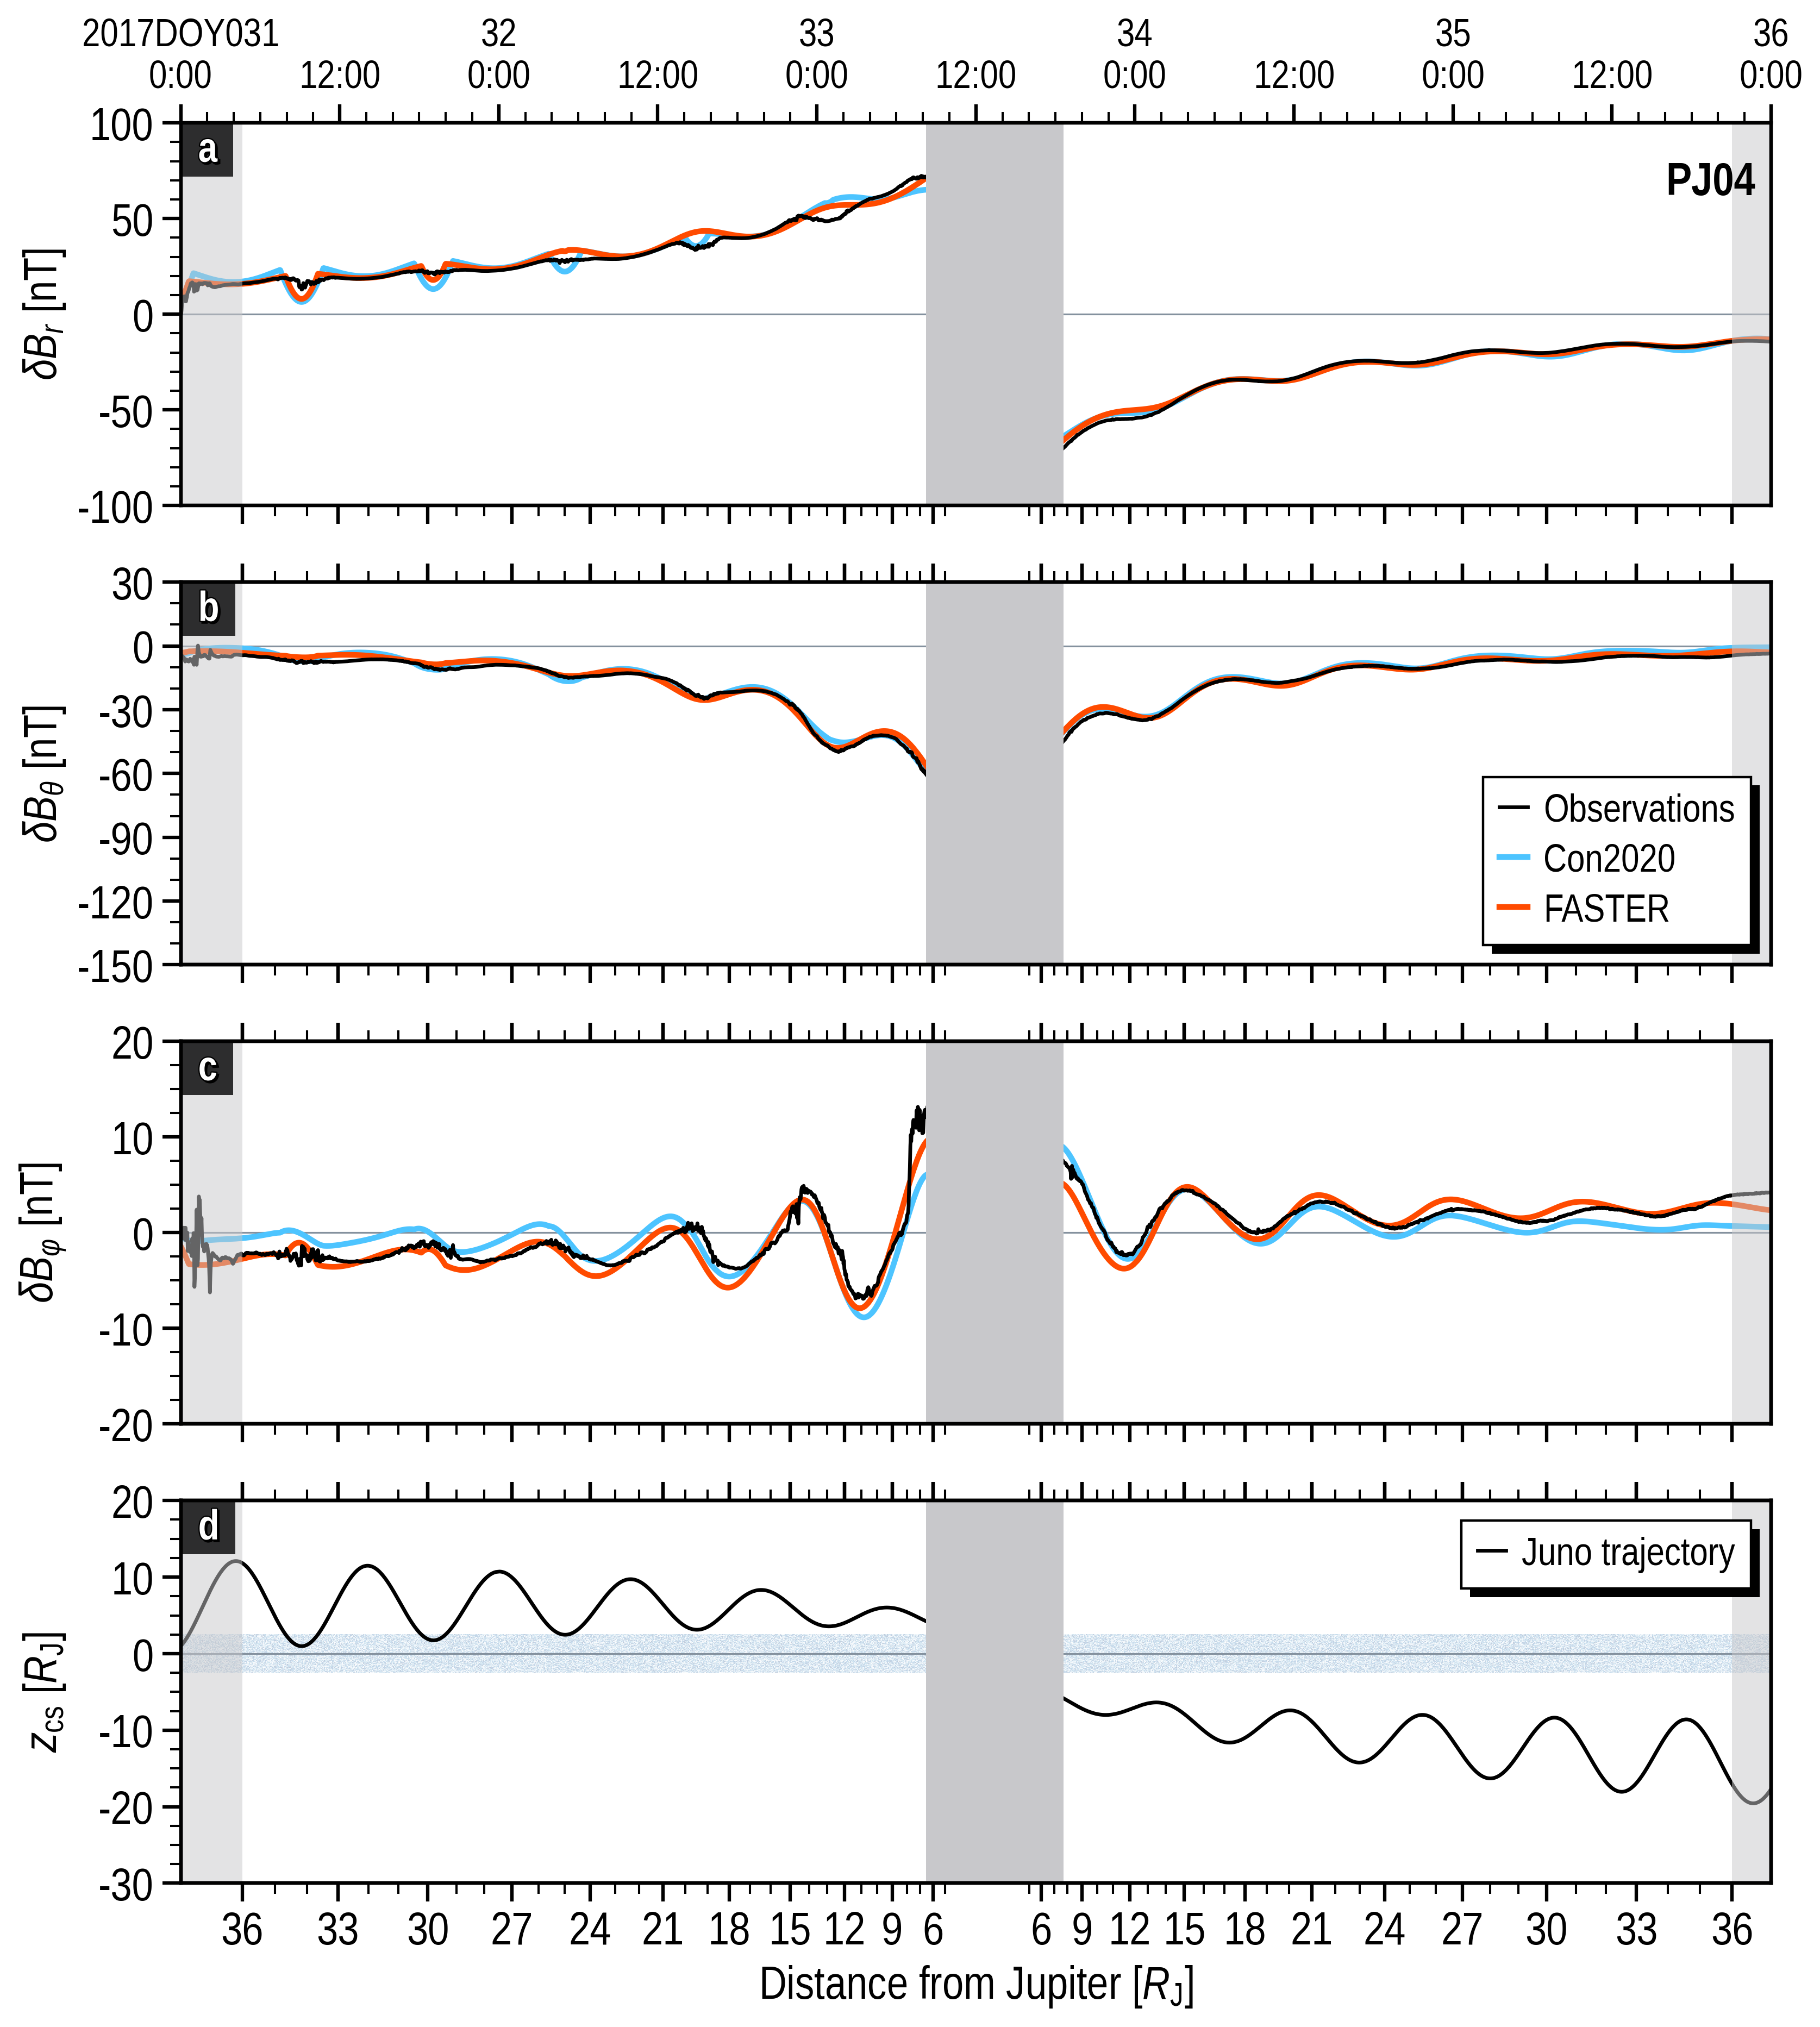

In [ ]:
F = ShareXaxis()
F.fontsize = 19
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=4, figsize=(10.0, 11.0), dpi='XL')
F.hspace = 0.2
F.initialize()

xticks = r_ticks[::3, 1]
xticklabels = r_ticks[::3, 0].astype(int)

F.set_xaxis(label=r'Distance from Jupiter [$R_{\rm J}$]',
            min=int(time_arr[0]),
            max=int(time_arr[-1])+1,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=None)
for i in range(4):
    F.ax[i].xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
for i in range(3):
    i += 1
    ax_upper = F.ax[i].twiny()
    ax_upper.set_xlim(int(time_arr[0]), int(time_arr[-1])+1)
    ax_upper.set_xticks(xticks)
    ax_upper.xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
    ax_upper.tick_params(labeltop=False)

F.set_yaxis(ax_idx=0,
            label=r'$\delta B_{r}$ [nT]',
            min=-100, max=100,
            ticks=np.linspace(-100, 100, 5),
            ticklabels=np.linspace(-100, 100, 5, dtype=int),
            minor_num=5)
F.set_yaxis(ax_idx=1,
            label=r'$\delta B_{\theta}$ [nT]',
            min=-150, max=30,
            ticks=np.linspace(-150, 30, 7),
            ticklabels=np.linspace(-150, 30, 7, dtype=int),
            minor_num=3)
F.set_yaxis(ax_idx=2,
            label=r'$\delta B_{\varphi}$ [nT]',
            min=-20, max=20,
            ticks=np.linspace(-20, 20, 5),
            ticklabels=np.linspace(-20, 20, 5, dtype=int),
            minor_num=4)
F.set_yaxis(ax_idx=3,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-30, max=20,
            ticks=np.linspace(-30, 20, 6),
            ticklabels=np.linspace(-30, 20, 6, dtype=int),
            minor_num=4)
F.ax[0].plot(time_arr, dBr, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[0].plot(time_arr, dBr1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[0].plot(time_arr, dBr2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[1].plot(time_arr, dBtheta1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[2].plot(time_arr, dBphi, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[2].plot(time_arr, dBphi1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[2].plot(time_arr, dBphi2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[3].plot(time_arr, z_cs, color='k',
             linewidth=1.5, label='Juno trajectory', zorder=1.0)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap="Blues",
    alpha=0.25,
    interpolation="nearest",
    aspect="auto",
)

# Shades near Jupiter (< 5.0 RJ)
inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[inner_idx[0]],
                    time_arr[inner_idx[-1]],
                    fc=UC.lightgray, ec=None, zorder=2.5)

# Shades in the outer region
outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[0],
                    time_arr[outer_idx[0]],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)
    F.ax[i].axvspan(time_arr[outer_idx[-1]],
                    time_arr[-1],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)

# y = 0 line
for i in range(F.nrows):
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=0.9)

# Time axis
timeax = F.ax[0].twiny()
timeax.set_xlim(31, 36)
timeax.set_xticks(np.arange(31, 36+0.1, 0.5))
timeax.set_xticklabels([date_list[0]+'\n0:00', '12:00',
                        '32\n0:00', '12:00',
                        '33\n0:00', '12:00', '34\n0:00', '12:00',
                        '35\n0:00', '12:00',
                        '36\n0:00'], fontsize=F.fontsize*0.85)
timeax.xaxis.set_minor_locator(ptick.AutoMinorLocator(6))

F.ax[0].text(0.99, 0.9, 'PJ'+str(PJ_num).zfill(2),
             color='k',
             fontweight='bold',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)

legend = F.legend(ax_idx=1,
                  ncol=1, markerscale=1.0,
                  loc='lower right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)
legend = F.legend(ax_idx=3,
                  ncol=1, markerscale=1.0,
                  loc='upper right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[3], d=0.7)

plt.savefig('img/compare_a0_a1_b1_36rj/PJ'+str(PJ_num).zfill(2)+'.pdf',
            bbox_inches='tight')

# PJ16のデータを読み込む

In [20]:
PJ_num = 16
date_list = ['2018DOY300', '2018DOY301', '2018DOY302',
             '2018DOY303', '2018DOY304', '2018DOY305']

dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
time_arr = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
JunoMLT = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

rx_pc *= 1/71492.0  # [RJ]
ry_pc *= 1/71492.0  # [RJ]
rz_pc *= 1/71492.0  # [RJ]

In [21]:
# 座標
r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
cos_phi = rx_pc/r_pc
sin_phi = ry_pc/r_pc
cos_theta = rz_pc/r_pc
sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
print('Distance [RJ]:', r_pc[0], r_pc[-1])

# ==============
# Internal field
Bx0_pc = np.zeros(time_arr.size)
By0_pc = np.zeros(time_arr.size)
Bz0_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                        ry_pc[i],
                                                        rz_pc[i])  # [nT]
dBx = Bx_pc - Bx0_pc
dBy = By_pc - By0_pc
dBz = Bz_pc - Bz0_pc
dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
dBphi = -dBx*sin_phi + dBy*cos_phi

# ======================
# Con2020 original value
jm.Con2020.Config(
    mu_i=con20_mu_i_tot[np.where(con20_pj_idx == PJ_num)],
    i_rho=con20_mu_i_rho[np.where(con20_pj_idx == PJ_num)],
)
dBx1_pc = np.zeros(time_arr.size)
dBy1_pc = np.zeros(time_arr.size)
dBz1_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    dBx1_pc[i], dBy1_pc[i], dBz1_pc[i] = jm.Con2020.Field(rx_pc[i],
                                                          ry_pc[i],
                                                          rz_pc[i])  # [nT]
dBr1_pc = dBx1_pc*sin_theta*cos_phi + dBy1_pc * \
    sin_theta*sin_phi + dBz1_pc*cos_theta
dBtheta1_pc = dBx1_pc*cos_theta*cos_phi + \
    dBy1_pc*cos_theta*sin_phi - dBz1_pc*sin_theta
dBphi1_pc = -dBx1_pc*sin_phi + dBy1_pc*cos_phi

Distance [RJ]: 40.923028958868535 43.08184308937457


In [22]:
# =========
# DoE model
csfield = CSField()

select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
print(f0[select_pj, 1], f0[select_pj, 3])

dBx2_pc = np.zeros(time_arr.size)
dBy2_pc = np.zeros(time_arr.size)
dBz2_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    csfield.config(
        i_phi0=f0[select_pj, 1],
        I_rho0=f0[select_pj, 3],
        a0=3.59746838E-6,
        MLT0=1.22795601,
        a1=-5.15316425,
        MLT1=-40.94971659,
        b1=3.64,
    )
    dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field(rx_pc[i],
                                                                ry_pc[i],
                                                                rz_pc[i],
                                                                JunoMLT[i])  # [T]

x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
dBx2_pc *= 1E+9    # [nT]
dBy2_pc *= 1E+9    # [nT]
dBz2_pc *= 1E+9    # [nT]
dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
    sin_theta*sin_phi + dBz2_pc*cos_theta
dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
    dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

5.1868686868686865e-05 4.385658724283503


In [23]:
# ===========================================================
# RMSE（Root Mean Squared Error）
# ===========================================================
x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
in_30rj = np.where(r_pc < 36.0)[0][0]
out_30rj = np.where(r_pc < 36.0)[0][-1]
if PJ_num in [17]:
    in_5rj = np.where(rho_cs < 8.0)[0][0]
    out_5rj = np.where(rho_cs < 8.0)[0][-1]
else:
    in_5rj = np.where(rho_cs < 5.0)[0][0]
    out_5rj = np.where(rho_cs < 5.0)[0][-1]
in_num = in_5rj-in_30rj-1
out_num = out_30rj-out_5rj-1

# ===========================================================
# Sys3 (x, y, z) -> CS (rho, phi, z)
# ===========================================================
dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr2_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta2_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi2_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr2_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta2_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi2_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (FASTER):', RMS_total)

RMS total (FASTER): 3.2044493478081266


In [24]:
# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr1_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta1_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi1_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr1_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta1_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi1_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (Con2020):', RMS_total)

RMS total (Con2020): 3.33801661137232


In [25]:
if PJ_num in [17]:
    r_ticks_ref = np.arange(8.0, 36.0+1, 1)
else:
    r_ticks_ref = np.arange(5.0, 36.0+1, 1)
r_ticks = np.zeros((r_ticks_ref.size*2, 2))
for i in range(r_ticks_ref.size):
    r_i = r_ticks_ref[-1]-i
    time_i = time_arr[np.where(r_pc < r_i)[0][0]]
    r_ticks[i, 0] = r_i
    r_ticks[i, 1] = time_i

    time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
    r_ticks[-i-1, 0] = r_i
    r_ticks[-i-1, 1] = time_i

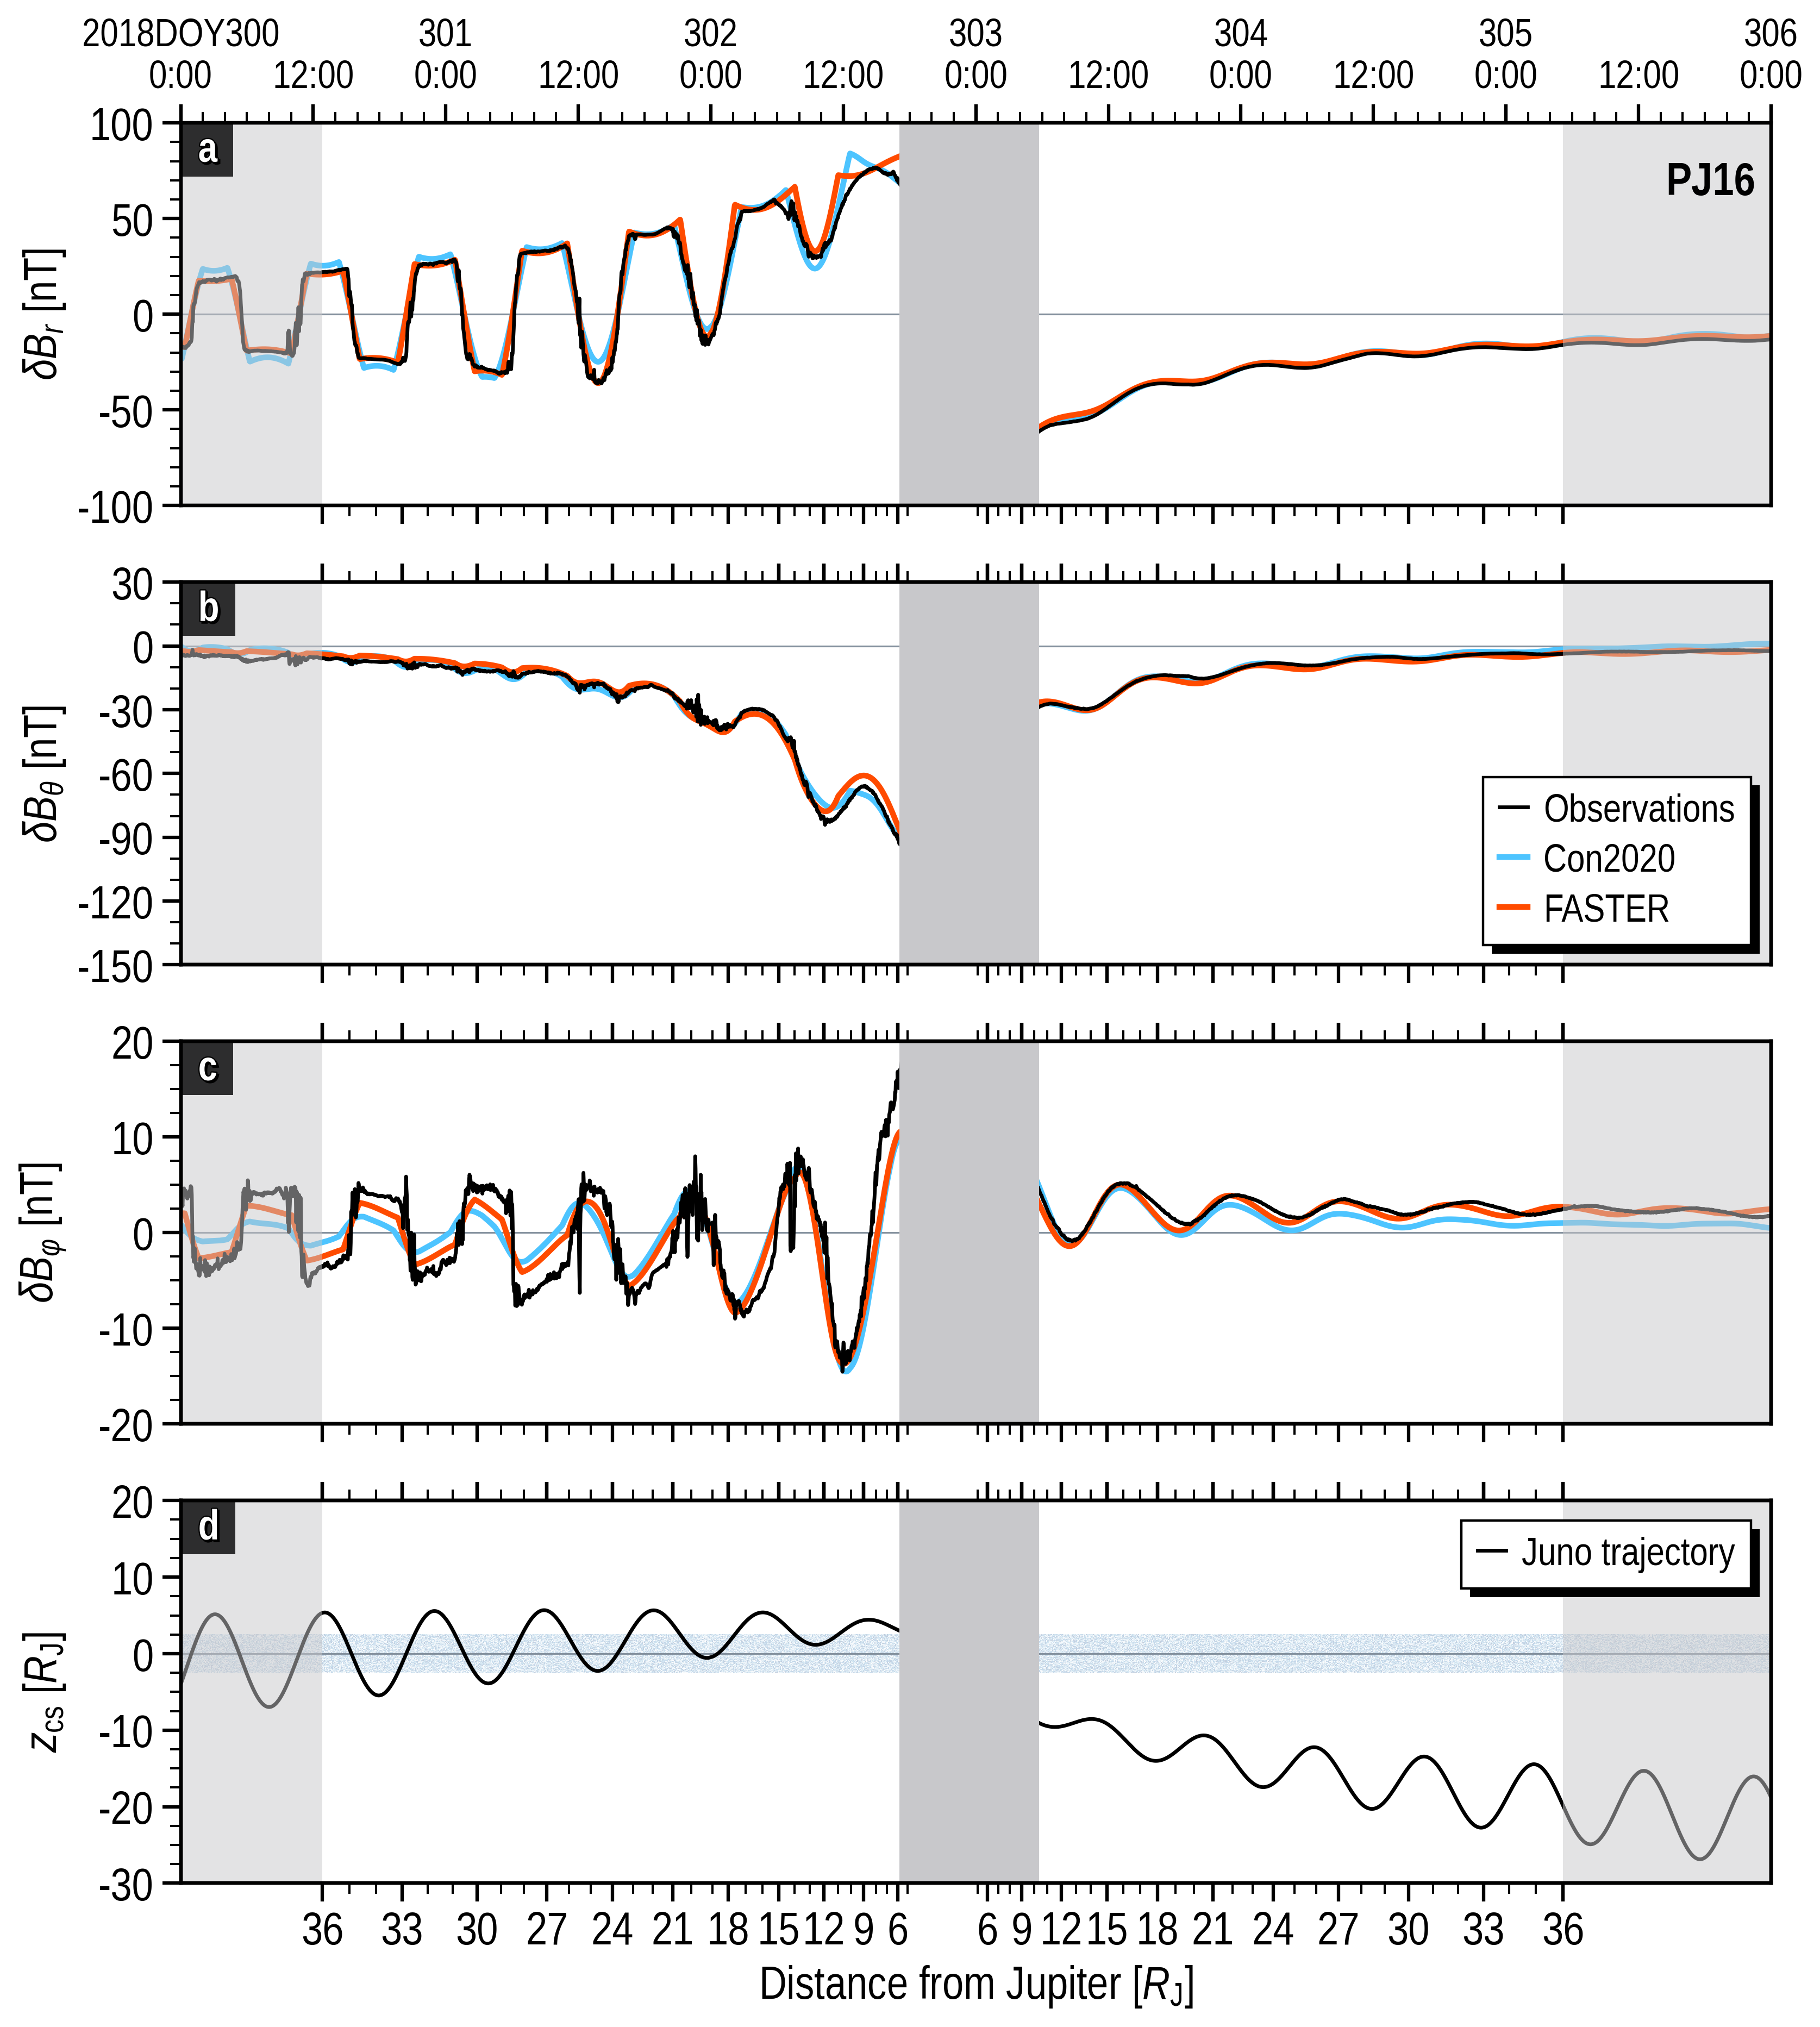

In [ ]:
F = ShareXaxis()
F.fontsize = 19
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=4, figsize=(10.0, 11.0), dpi='XL')
F.hspace = 0.2
F.initialize()

xticks = r_ticks[::3, 1]
xticklabels = r_ticks[::3, 0].astype(int)

F.set_xaxis(label=r'Distance from Jupiter [$R_{\rm J}$]',
            min=int(time_arr[0]),
            max=int(time_arr[-1])+1,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=None)
for i in range(4):
    F.ax[i].xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
for i in range(3):
    i += 1
    ax_upper = F.ax[i].twiny()
    ax_upper.set_xlim(int(time_arr[0]), int(time_arr[-1])+1)
    ax_upper.set_xticks(xticks)
    ax_upper.xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
    ax_upper.tick_params(labeltop=False)

F.set_yaxis(ax_idx=0,
            label=r'$\delta B_{r}$ [nT]',
            min=-100, max=100,
            ticks=np.linspace(-100, 100, 5),
            ticklabels=np.linspace(-100, 100, 5, dtype=int),
            minor_num=5)
F.set_yaxis(ax_idx=1,
            label=r'$\delta B_{\theta}$ [nT]',
            min=-150, max=30,
            ticks=np.linspace(-150, 30, 7),
            ticklabels=np.linspace(-150, 30, 7, dtype=int),
            minor_num=3)
F.set_yaxis(ax_idx=2,
            label=r'$\delta B_{\varphi}$ [nT]',
            min=-20, max=20,
            ticks=np.linspace(-20, 20, 5),
            ticklabels=np.linspace(-20, 20, 5, dtype=int),
            minor_num=4)
F.set_yaxis(ax_idx=3,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-30, max=20,
            ticks=np.linspace(-30, 20, 6),
            ticklabels=np.linspace(-30, 20, 6, dtype=int),
            minor_num=4)
F.ax[0].plot(time_arr, dBr, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[0].plot(time_arr, dBr1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[0].plot(time_arr, dBr2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[1].plot(time_arr, dBtheta1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[2].plot(time_arr, dBphi, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[2].plot(time_arr, dBphi1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[2].plot(time_arr, dBphi2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[3].plot(time_arr, z_cs, color='k',
             linewidth=1.5, label='Juno trajectory', zorder=1.0)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap="Blues",
    alpha=0.25,
    interpolation="nearest",
    aspect="auto",
)

# Shades near Jupiter (< 5.0 RJ)
inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[inner_idx[0]],
                    time_arr[inner_idx[-1]],
                    fc=UC.lightgray, ec=None, zorder=2.5)

# Shades in the outer region
outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[0],
                    time_arr[outer_idx[0]],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)
    F.ax[i].axvspan(time_arr[outer_idx[-1]],
                    time_arr[-1],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)

# y = 0 line
for i in range(F.nrows):
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=0.9)

# Time axis
timeax = F.ax[0].twiny()
timeax.set_xlim(300, 306)
timeax.set_xticks(np.arange(300, 306+0.1, 0.5))
timeax.set_xticklabels([date_list[0]+'\n0:00', '12:00',
                        '301\n0:00', '12:00',
                        '302\n0:00', '12:00', '303\n0:00', '12:00',
                        '304\n0:00', '12:00', '305\n0:00', '12:00',
                        '306\n0:00'], fontsize=F.fontsize*0.85)
timeax.xaxis.set_minor_locator(ptick.AutoMinorLocator(6))

F.ax[0].text(0.99, 0.9, 'PJ'+str(PJ_num).zfill(2),
             color='k',
             fontweight='bold',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)

legend = F.legend(ax_idx=1,
                  ncol=1, markerscale=1.0,
                  loc='lower right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)
legend = F.legend(ax_idx=3,
                  ncol=1, markerscale=1.0,
                  loc='upper right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[3], d=0.7)

plt.savefig('img/compare_a0_a1_b1_36rj/PJ'+str(PJ_num).zfill(2)+'.pdf',
            bbox_inches='tight')

# PJ24のデータを読み込む

In [27]:
PJ_num = 24
date_list = ['2019DOY358', '2019DOY359', '2019DOY360',
             '2019DOY361', '2019DOY362', '2019DOY363']

dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
time_arr = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
JunoMLT = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

rx_pc *= 1/71492.0  # [RJ]
ry_pc *= 1/71492.0  # [RJ]
rz_pc *= 1/71492.0  # [RJ]

In [28]:
# 座標
r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
cos_phi = rx_pc/r_pc
sin_phi = ry_pc/r_pc
cos_theta = rz_pc/r_pc
sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
print('Distance [RJ]:', r_pc[0], r_pc[-1])

# ==============
# Internal field
Bx0_pc = np.zeros(time_arr.size)
By0_pc = np.zeros(time_arr.size)
Bz0_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                        ry_pc[i],
                                                        rz_pc[i])  # [nT]
dBx = Bx_pc - Bx0_pc
dBy = By_pc - By0_pc
dBz = Bz_pc - Bz0_pc
dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
dBphi = -dBx*sin_phi + dBy*cos_phi

# ======================
# Con2020 original value
jm.Con2020.Config(
    mu_i=con20_mu_i_tot[np.where(con20_pj_idx == PJ_num)],
    i_rho=con20_mu_i_rho[np.where(con20_pj_idx == PJ_num)],
)
dBx1_pc = np.zeros(time_arr.size)
dBy1_pc = np.zeros(time_arr.size)
dBz1_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    dBx1_pc[i], dBy1_pc[i], dBz1_pc[i] = jm.Con2020.Field(rx_pc[i],
                                                          ry_pc[i],
                                                          rz_pc[i])  # [nT]
dBr1_pc = dBx1_pc*sin_theta*cos_phi + dBy1_pc * \
    sin_theta*sin_phi + dBz1_pc*cos_theta
dBtheta1_pc = dBx1_pc*cos_theta*cos_phi + \
    dBy1_pc*cos_theta*sin_phi - dBz1_pc*sin_theta
dBphi1_pc = -dBx1_pc*sin_phi + dBy1_pc*cos_phi

Distance [RJ]: 39.599332227557895 44.29313884767689


In [29]:
# =========
# DoE model
csfield = CSField()

select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
print(f0[select_pj, 1], f0[select_pj, 3])

dBx2_pc = np.zeros(time_arr.size)
dBy2_pc = np.zeros(time_arr.size)
dBz2_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    csfield.config(
        i_phi0=f0[select_pj, 1],
        I_rho0=f0[select_pj, 3],
        a0=3.59746838E-6,
        MLT0=1.22795601,
        a1=-5.15316425,
        MLT1=-40.94971659,
        b1=3.64,
    )
    dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field(rx_pc[i],
                                                                ry_pc[i],
                                                                rz_pc[i],
                                                                JunoMLT[i])  # [T]

x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
dBx2_pc *= 1E+9    # [nT]
dBy2_pc *= 1E+9    # [nT]
dBz2_pc *= 1E+9    # [nT]
dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
    sin_theta*sin_phi + dBz2_pc*cos_theta
dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
    dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

5.0707070707070706e-05 6.6780569035989945


In [30]:
# ===========================================================
# RMSE（Root Mean Squared Error）
# ===========================================================
x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
in_30rj = np.where(r_pc < 36.0)[0][0]
out_30rj = np.where(r_pc < 36.0)[0][-1]
if PJ_num in [17]:
    in_5rj = np.where(rho_cs < 8.0)[0][0]
    out_5rj = np.where(rho_cs < 8.0)[0][-1]
else:
    in_5rj = np.where(rho_cs < 5.0)[0][0]
    out_5rj = np.where(rho_cs < 5.0)[0][-1]
in_num = in_5rj-in_30rj-1
out_num = out_30rj-out_5rj-1

# ===========================================================
# Sys3 (x, y, z) -> CS (rho, phi, z)
# ===========================================================
dBx_cs, dBy_cs, dBz_cs = csfield._sys3_2_cs(dBx, dBy, dBz)
dBrho_cs = dBx_cs*np.cos(phi_cs) + dBy_cs*np.sin(phi_cs)
dBphi_cs = -dBx_cs*np.sin(phi_cs) + dBy_cs*np.cos(phi_cs)

dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr2_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta2_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi2_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr2_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta2_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi2_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (FASTER):', RMS_total)

RMS total (FASTER): 4.07751035629057


In [31]:
# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr1_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta1_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi1_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr1_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta1_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi1_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (Con2020):', RMS_total)

RMS total (Con2020): 4.269937005942099


In [32]:
if PJ_num in [17]:
    r_ticks_ref = np.arange(8.0, 36.0+1, 1)
else:
    r_ticks_ref = np.arange(5.0, 36.0+1, 1)
r_ticks = np.zeros((r_ticks_ref.size*2, 2))
for i in range(r_ticks_ref.size):
    r_i = r_ticks_ref[-1]-i
    time_i = time_arr[np.where(r_pc < r_i)[0][0]]
    r_ticks[i, 0] = r_i
    r_ticks[i, 1] = time_i

    time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
    r_ticks[-i-1, 0] = r_i
    r_ticks[-i-1, 1] = time_i

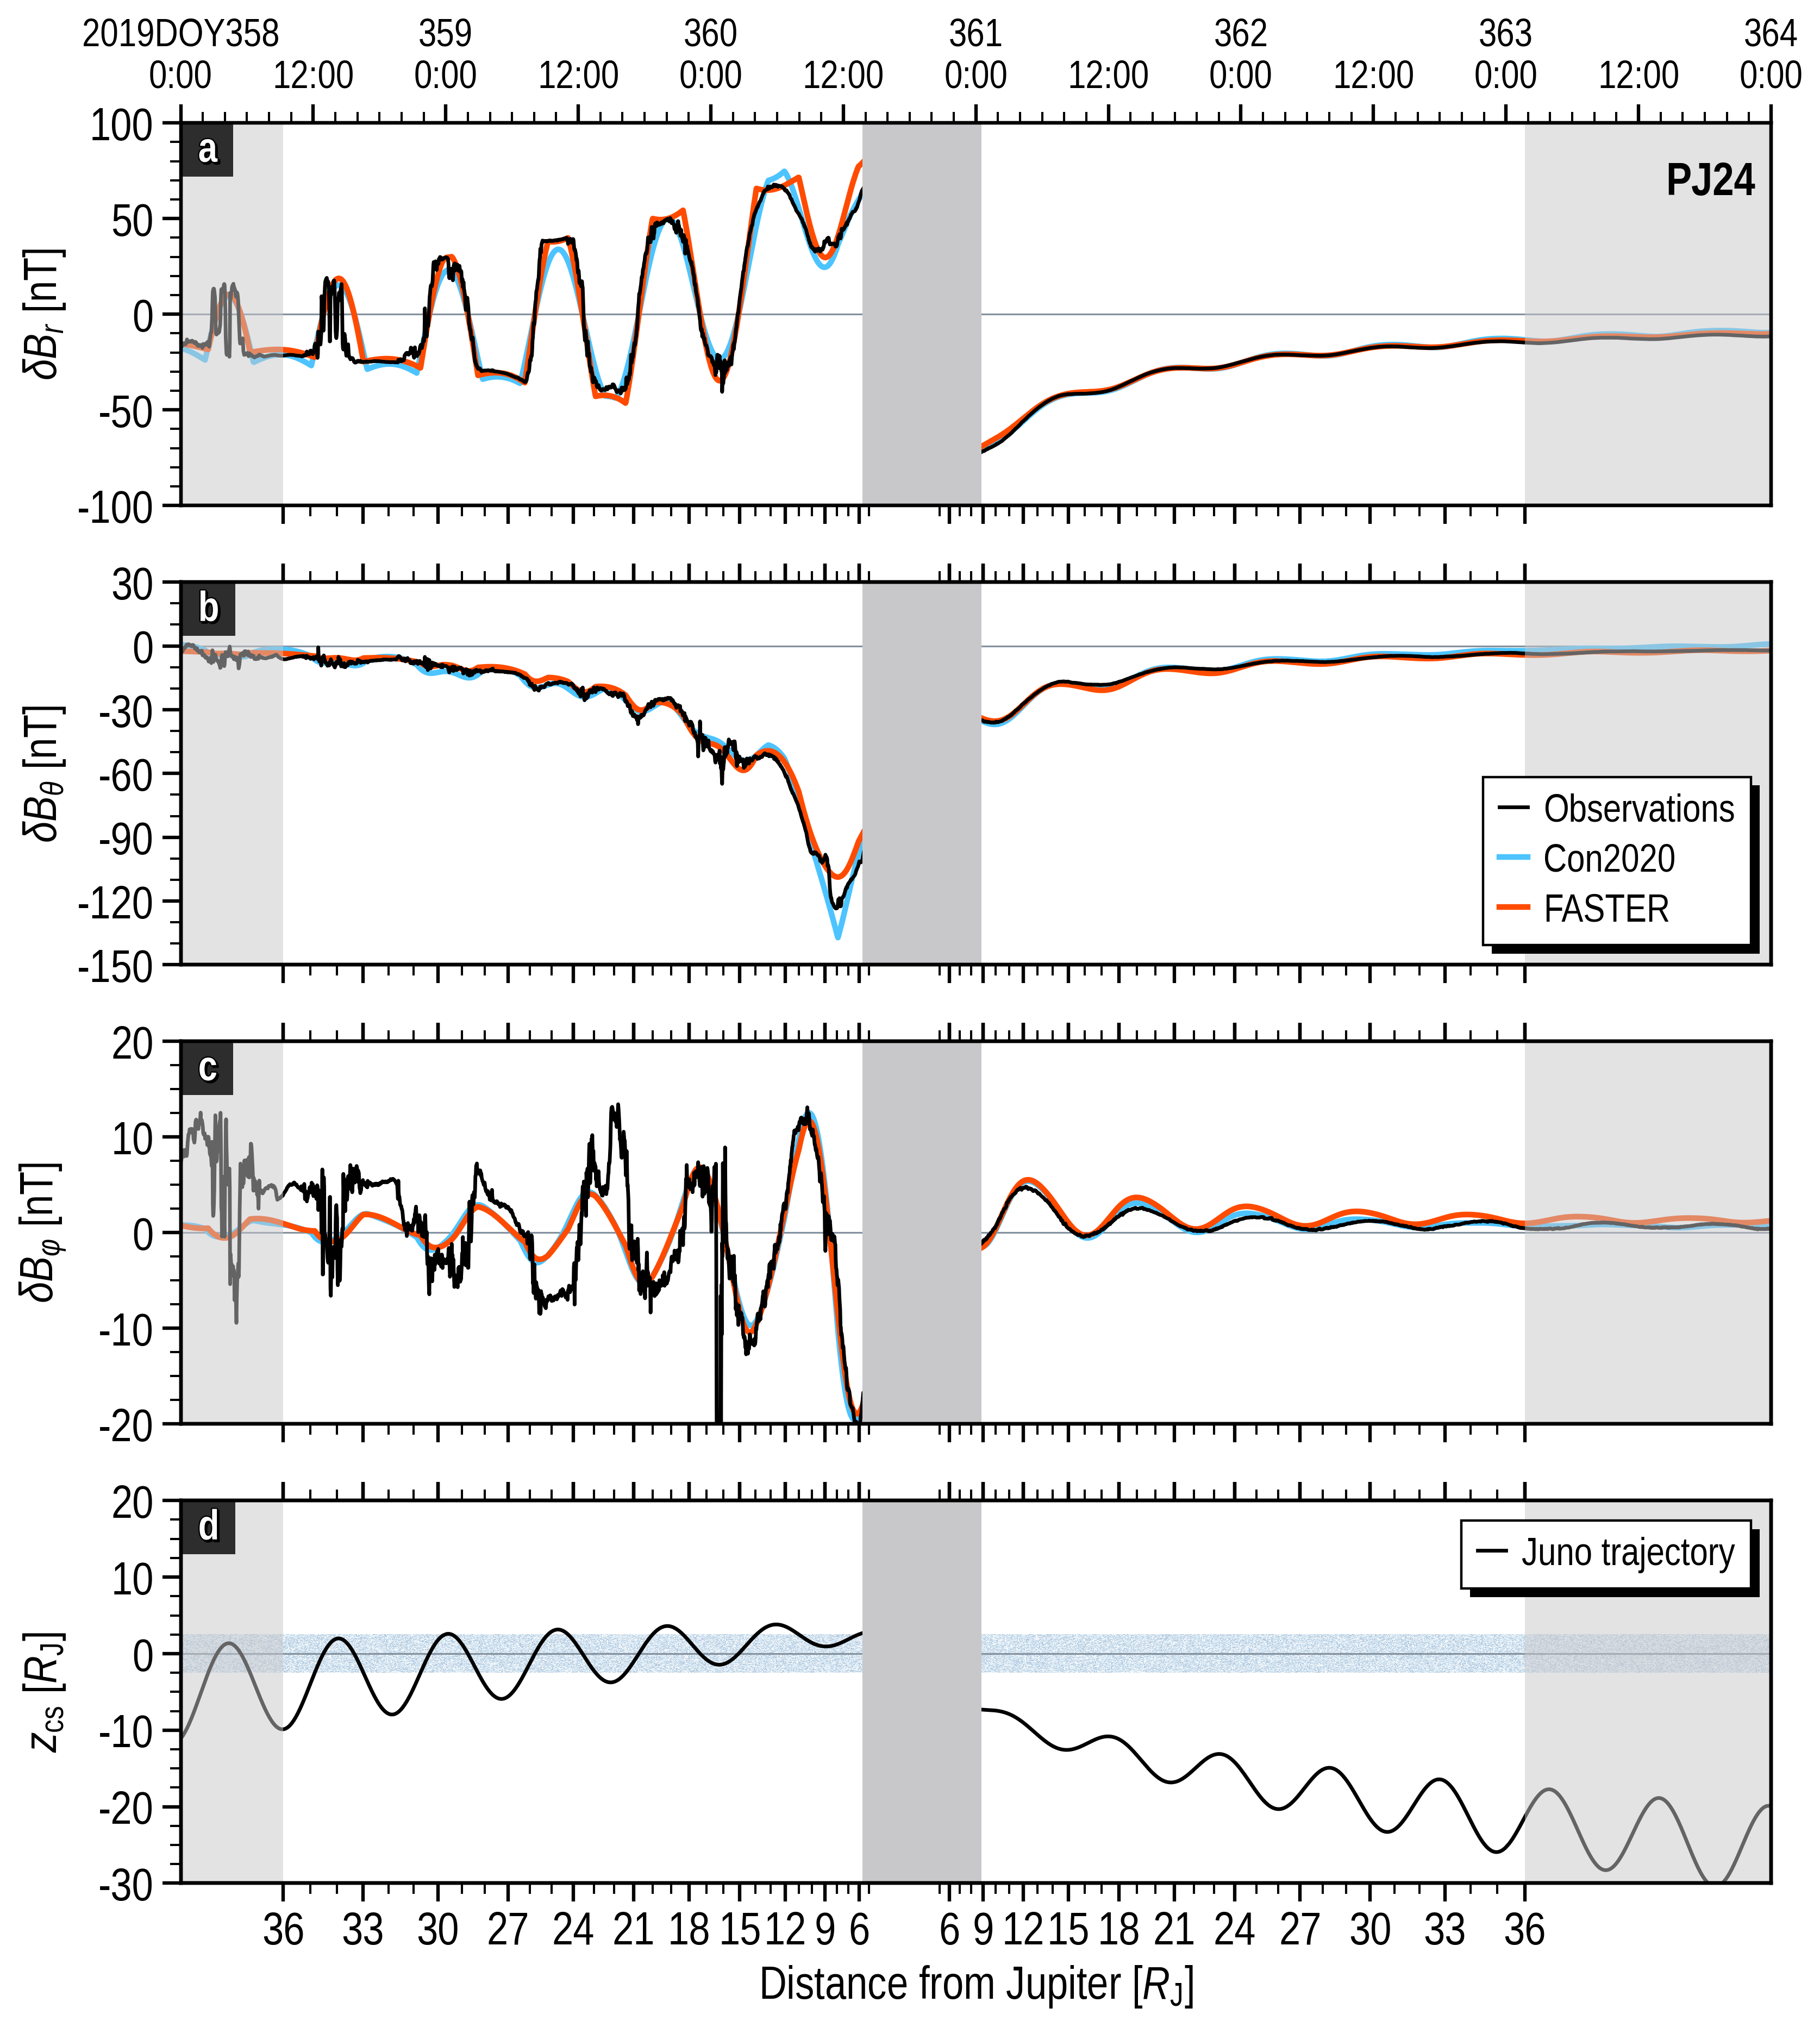

In [67]:
F = ShareXaxis()
F.fontsize = 19
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=4, figsize=(10.0, 11.0), dpi='XL')
F.hspace = 0.2
F.initialize()

xticks = r_ticks[::3, 1]
xticklabels = r_ticks[::3, 0].astype(int)

F.set_xaxis(label=r'Distance from Jupiter [$R_{\rm J}$]',
            min=int(time_arr[0]),
            max=int(time_arr[-1])+1,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=None)
for i in range(4):
    F.ax[i].xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
for i in range(3):
    i += 1
    ax_upper = F.ax[i].twiny()
    ax_upper.set_xlim(int(time_arr[0]), int(time_arr[-1])+1)
    ax_upper.set_xticks(xticks)
    ax_upper.xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
    ax_upper.tick_params(labeltop=False)

F.set_yaxis(ax_idx=0,
            label=r'$\delta B_{r}$ [nT]',
            min=-100, max=100,
            ticks=np.linspace(-100, 100, 5),
            ticklabels=np.linspace(-100, 100, 5, dtype=int),
            minor_num=5)
F.set_yaxis(ax_idx=1,
            label=r'$\delta B_{\theta}$ [nT]',
            min=-150, max=30,
            ticks=np.linspace(-150, 30, 7),
            ticklabels=np.linspace(-150, 30, 7, dtype=int),
            minor_num=3)
F.set_yaxis(ax_idx=2,
            label=r'$\delta B_{\varphi}$ [nT]',
            min=-20, max=20,
            ticks=np.linspace(-20, 20, 5),
            ticklabels=np.linspace(-20, 20, 5, dtype=int),
            minor_num=4)
F.set_yaxis(ax_idx=3,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-30, max=20,
            ticks=np.linspace(-30, 20, 6),
            ticklabels=np.linspace(-30, 20, 6, dtype=int),
            minor_num=4)
F.ax[0].plot(time_arr, dBr, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[0].plot(time_arr, dBr1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[0].plot(time_arr, dBr2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[1].plot(time_arr, dBtheta1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[2].plot(time_arr, dBphi, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[2].plot(time_arr, dBphi1_pc, color=UC.lightblue,
             linewidth=2.3, label='Con2020', zorder=1.0)
F.ax[2].plot(time_arr, dBphi2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[3].plot(time_arr, z_cs, color='k',
             linewidth=1.5, label='Juno trajectory', zorder=1.0)

colors = [
    "#fffdfb",  # オフホワイト
    "#f8d9d4",  # 淡いピンク
    "#f7a18c",  # コーラル
    "#ff4b1b",  # 鮮やかなオレンジレッド
    "#ff681c",  # オレンジ
    "#ff9b2f",  # 明るいオレンジ
    "#ffd36b",  # 淡いオレンジイエロー
    "#fff0ad",  # 淡い黄色
    "#fffdf2",  # アイボリー
]

cmap_orange = LinearSegmentedColormap.from_list(
    "orange_glow",
    colors,
    N=256,
)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap="Blues",
    alpha=0.3,
    interpolation="nearest",
    aspect="auto",
)

# Shades near Jupiter (< 5.0 RJ)
inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[inner_idx[0]],
                    time_arr[inner_idx[-1]],
                    fc=UC.lightgray, ec=None, zorder=2.5)

# Shades in the outer region
outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[0],
                    time_arr[outer_idx[0]],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)
    F.ax[i].axvspan(time_arr[outer_idx[-1]],
                    time_arr[-1],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)

# y = 0 line
for i in range(F.nrows):
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=0.9)

# Time axis
timeax = F.ax[0].twiny()
timeax.set_xlim(358, 364)
timeax.set_xticks(np.arange(358, 364+0.1, 0.5))
timeax.set_xticklabels([date_list[0]+'\n0:00', '12:00',
                        '359\n0:00', '12:00',
                        '360\n0:00', '12:00', '361\n0:00', '12:00',
                        '362\n0:00', '12:00', '363\n0:00', '12:00',
                        '364\n0:00'], fontsize=F.fontsize*0.85)
timeax.xaxis.set_minor_locator(ptick.AutoMinorLocator(6))

F.ax[0].text(0.99, 0.9, 'PJ'+str(PJ_num).zfill(2),
             color='k',
             fontweight='bold',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)

legend = F.legend(ax_idx=1,
                  ncol=1, markerscale=1.0,
                  loc='lower right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)
legend = F.legend(ax_idx=3,
                  ncol=1, markerscale=1.0,
                  loc='upper right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[3], d=0.7)

plt.savefig('img/compare_a0_a1_b1_36rj/PJ'+str(PJ_num).zfill(2)+'.pdf',
            bbox_inches='tight')

# PJ52のデータを読み込む

In [99]:
PJ_num = 52
date_list = ['2023DOY171', '2023DOY172', '2023DOY173',
             '2023DOY174', '2023DOY175', '2023DOY176',
             '2023DOY177', '2023DOY178']

dir = 'data/FGM/PJ'+str(PJ_num).zfill(2)+'/'
time_arr = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_time.txt')
Bx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bx.txt')
By_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_By.txt')
Bz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_Bz.txt')
rx_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rx.txt')
ry_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_ry.txt')
rz_pc = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_rz.txt')
JunoMLT = np.loadtxt(dir+'fgm_PJ'+str(PJ_num).zfill(2)+'_pc_2min_JunoMLT.txt')

rx_pc *= 1/71492.0  # [RJ]
ry_pc *= 1/71492.0  # [RJ]
rz_pc *= 1/71492.0  # [RJ]
time_arr *= 1/(24*3600)

Bx_pc = Bx_pc[np.where(time_arr < 177.)]
By_pc = By_pc[np.where(time_arr < 177.)]
Bz_pc = Bz_pc[np.where(time_arr < 177.)]
rx_pc = rx_pc[np.where(time_arr < 177.)]
ry_pc = ry_pc[np.where(time_arr < 177.)]
rz_pc = rz_pc[np.where(time_arr < 177.)]
JunoMLT = JunoMLT[np.where(time_arr < 177.)]
time_arr = time_arr[np.where(time_arr < 177.)]

print(time_arr[0], time_arr[-1])

171.0111111111111 176.9986111111111


In [100]:
# 座標
r_pc = np.sqrt(rx_pc**2+ry_pc**2+rz_pc**2)
cos_phi = rx_pc/r_pc
sin_phi = ry_pc/r_pc
cos_theta = rz_pc/r_pc
sin_theta = np.sqrt(rx_pc**2+ry_pc**2)/r_pc
print('Distance [RJ]:', r_pc[0], r_pc[-1])

# ==============
# Internal field
Bx0_pc = np.zeros(time_arr.size)
By0_pc = np.zeros(time_arr.size)
Bz0_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    Bx0_pc[i], By0_pc[i], Bz0_pc[i] = jm.Internal.Field(rx_pc[i],
                                                        ry_pc[i],
                                                        rz_pc[i])  # [nT]
dBx = Bx_pc - Bx0_pc
dBy = By_pc - By0_pc
dBz = Bz_pc - Bz0_pc
dBr = dBx*sin_theta*cos_phi + dBy*sin_theta*sin_phi + dBz*cos_theta
dBtheta = dBx*cos_theta*cos_phi + dBy*cos_theta*sin_phi - dBz*sin_theta
dBphi = -dBx*sin_phi + dBy*cos_phi

Distance [RJ]: 43.2413201059927 38.62080773824182


In [101]:
# =========
# DoE model
csfield = CSField()

select_pj = np.where(np.array(PJ_list) == PJ_num)[0][0]
print(f0[select_pj, 1], f0[select_pj, 3])

dBx2_pc = np.zeros(time_arr.size)
dBy2_pc = np.zeros(time_arr.size)
dBz2_pc = np.zeros(time_arr.size)
for i in range(time_arr.size):
    csfield.config(
        i_phi0=f0[select_pj, 1],
        I_rho0=f0[select_pj, 3],
        a0=3.59746838E-6,
        MLT0=1.22795601,
        a1=-5.15316425,
        MLT1=-40.94971659,
        b1=3.64,
    )
    dBx2_pc[i], dBy2_pc[i], dBz2_pc[i] = csfield.magnetic_field(rx_pc[i],
                                                                ry_pc[i],
                                                                rz_pc[i],
                                                                JunoMLT[i])  # [T]

x_cs, y_cs, z_cs = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
dBx2_pc *= 1E+9    # [nT]
dBy2_pc *= 1E+9    # [nT]
dBz2_pc *= 1E+9    # [nT]
dBr2_pc = dBx2_pc*sin_theta*cos_phi + dBy2_pc * \
    sin_theta*sin_phi + dBz2_pc*cos_theta
dBtheta2_pc = dBx2_pc*cos_theta*cos_phi + \
    dBy2_pc*cos_theta*sin_phi - dBz2_pc*sin_theta
dBphi2_pc = -dBx2_pc*sin_phi + dBy2_pc*cos_phi

4.4666666666666664e-05 2.1467949973637297


In [102]:
# ===========================================================
# RMSE（Root Mean Squared Error）
# ===========================================================
x_cs, y_cs, _ = csfield._sys3_2_cs(rx_pc, ry_pc, rz_pc)
phi_cs = np.arctan2(y_cs, x_cs)
rho_cs = np.sqrt(x_cs**2 + y_cs**2)
in_30rj = np.where(r_pc < 36.0)[0][0]
out_30rj = np.where(r_pc < 36.0)[0][-1]
if PJ_num in [17]:
    in_5rj = np.where(rho_cs < 8.0)[0][0]
    out_5rj = np.where(rho_cs < 8.0)[0][-1]
else:
    in_5rj = np.where(rho_cs < 5.0)[0][0]
    out_5rj = np.where(rho_cs < 5.0)[0][-1]
in_num = in_5rj-in_30rj-1
out_num = out_30rj-out_5rj-1

# ===========================================================
# Sys3 (x, y, z) -> CS (rho, phi, z)
# ===========================================================
dBx2_cs, dBy2_cs, dBz2_cs = csfield._sys3_2_cs(dBx2_pc, dBy2_pc, dBz2_pc)
dBrho2_cs = dBx2_cs*np.cos(phi_cs) + dBy2_cs*np.sin(phi_cs)
dBphi2_cs = -dBx2_cs*np.sin(phi_cs) + dBy2_cs*np.cos(phi_cs)

# ===========================================================
# Total RMSE
# ===========================================================
RMS_total = math.sqrt(
    (
        np.sum(
            (dBr[in_30rj:in_5rj]-dBr2_pc[in_30rj:in_5rj])**2 +
            (dBtheta[in_30rj:in_5rj]-dBtheta2_pc[in_30rj:in_5rj])**2 +
            (dBphi[in_30rj:in_5rj]-dBphi2_pc[in_30rj:in_5rj])**2
        ) + np.sum(
            (dBr[out_5rj:out_30rj]-dBr2_pc[out_5rj:out_30rj])**2 +
            (dBtheta[out_5rj:out_30rj]-dBtheta2_pc[out_5rj:out_30rj])**2 +
            (dBphi[out_5rj:out_30rj]-dBphi2_pc[out_5rj:out_30rj])**2
        )
    )/(3*in_num+3*out_num))
print('RMS total (FASTER):', RMS_total)

RMS total (FASTER): 3.2291636568714734


In [103]:
if PJ_num in [17]:
    r_ticks_ref = np.arange(8.0, 36.0+1, 1)
else:
    r_ticks_ref = np.arange(5.0, 36.0+1, 1)
r_ticks = np.zeros((r_ticks_ref.size*2, 2))
for i in range(r_ticks_ref.size):
    r_i = r_ticks_ref[-1]-i
    time_i = time_arr[np.where(r_pc < r_i)[0][0]]
    r_ticks[i, 0] = r_i
    r_ticks[i, 1] = time_i

    time_i = time_arr[np.where(r_pc < r_i)[0][-1]]
    r_ticks[-i-1, 0] = r_i
    r_ticks[-i-1, 1] = time_i

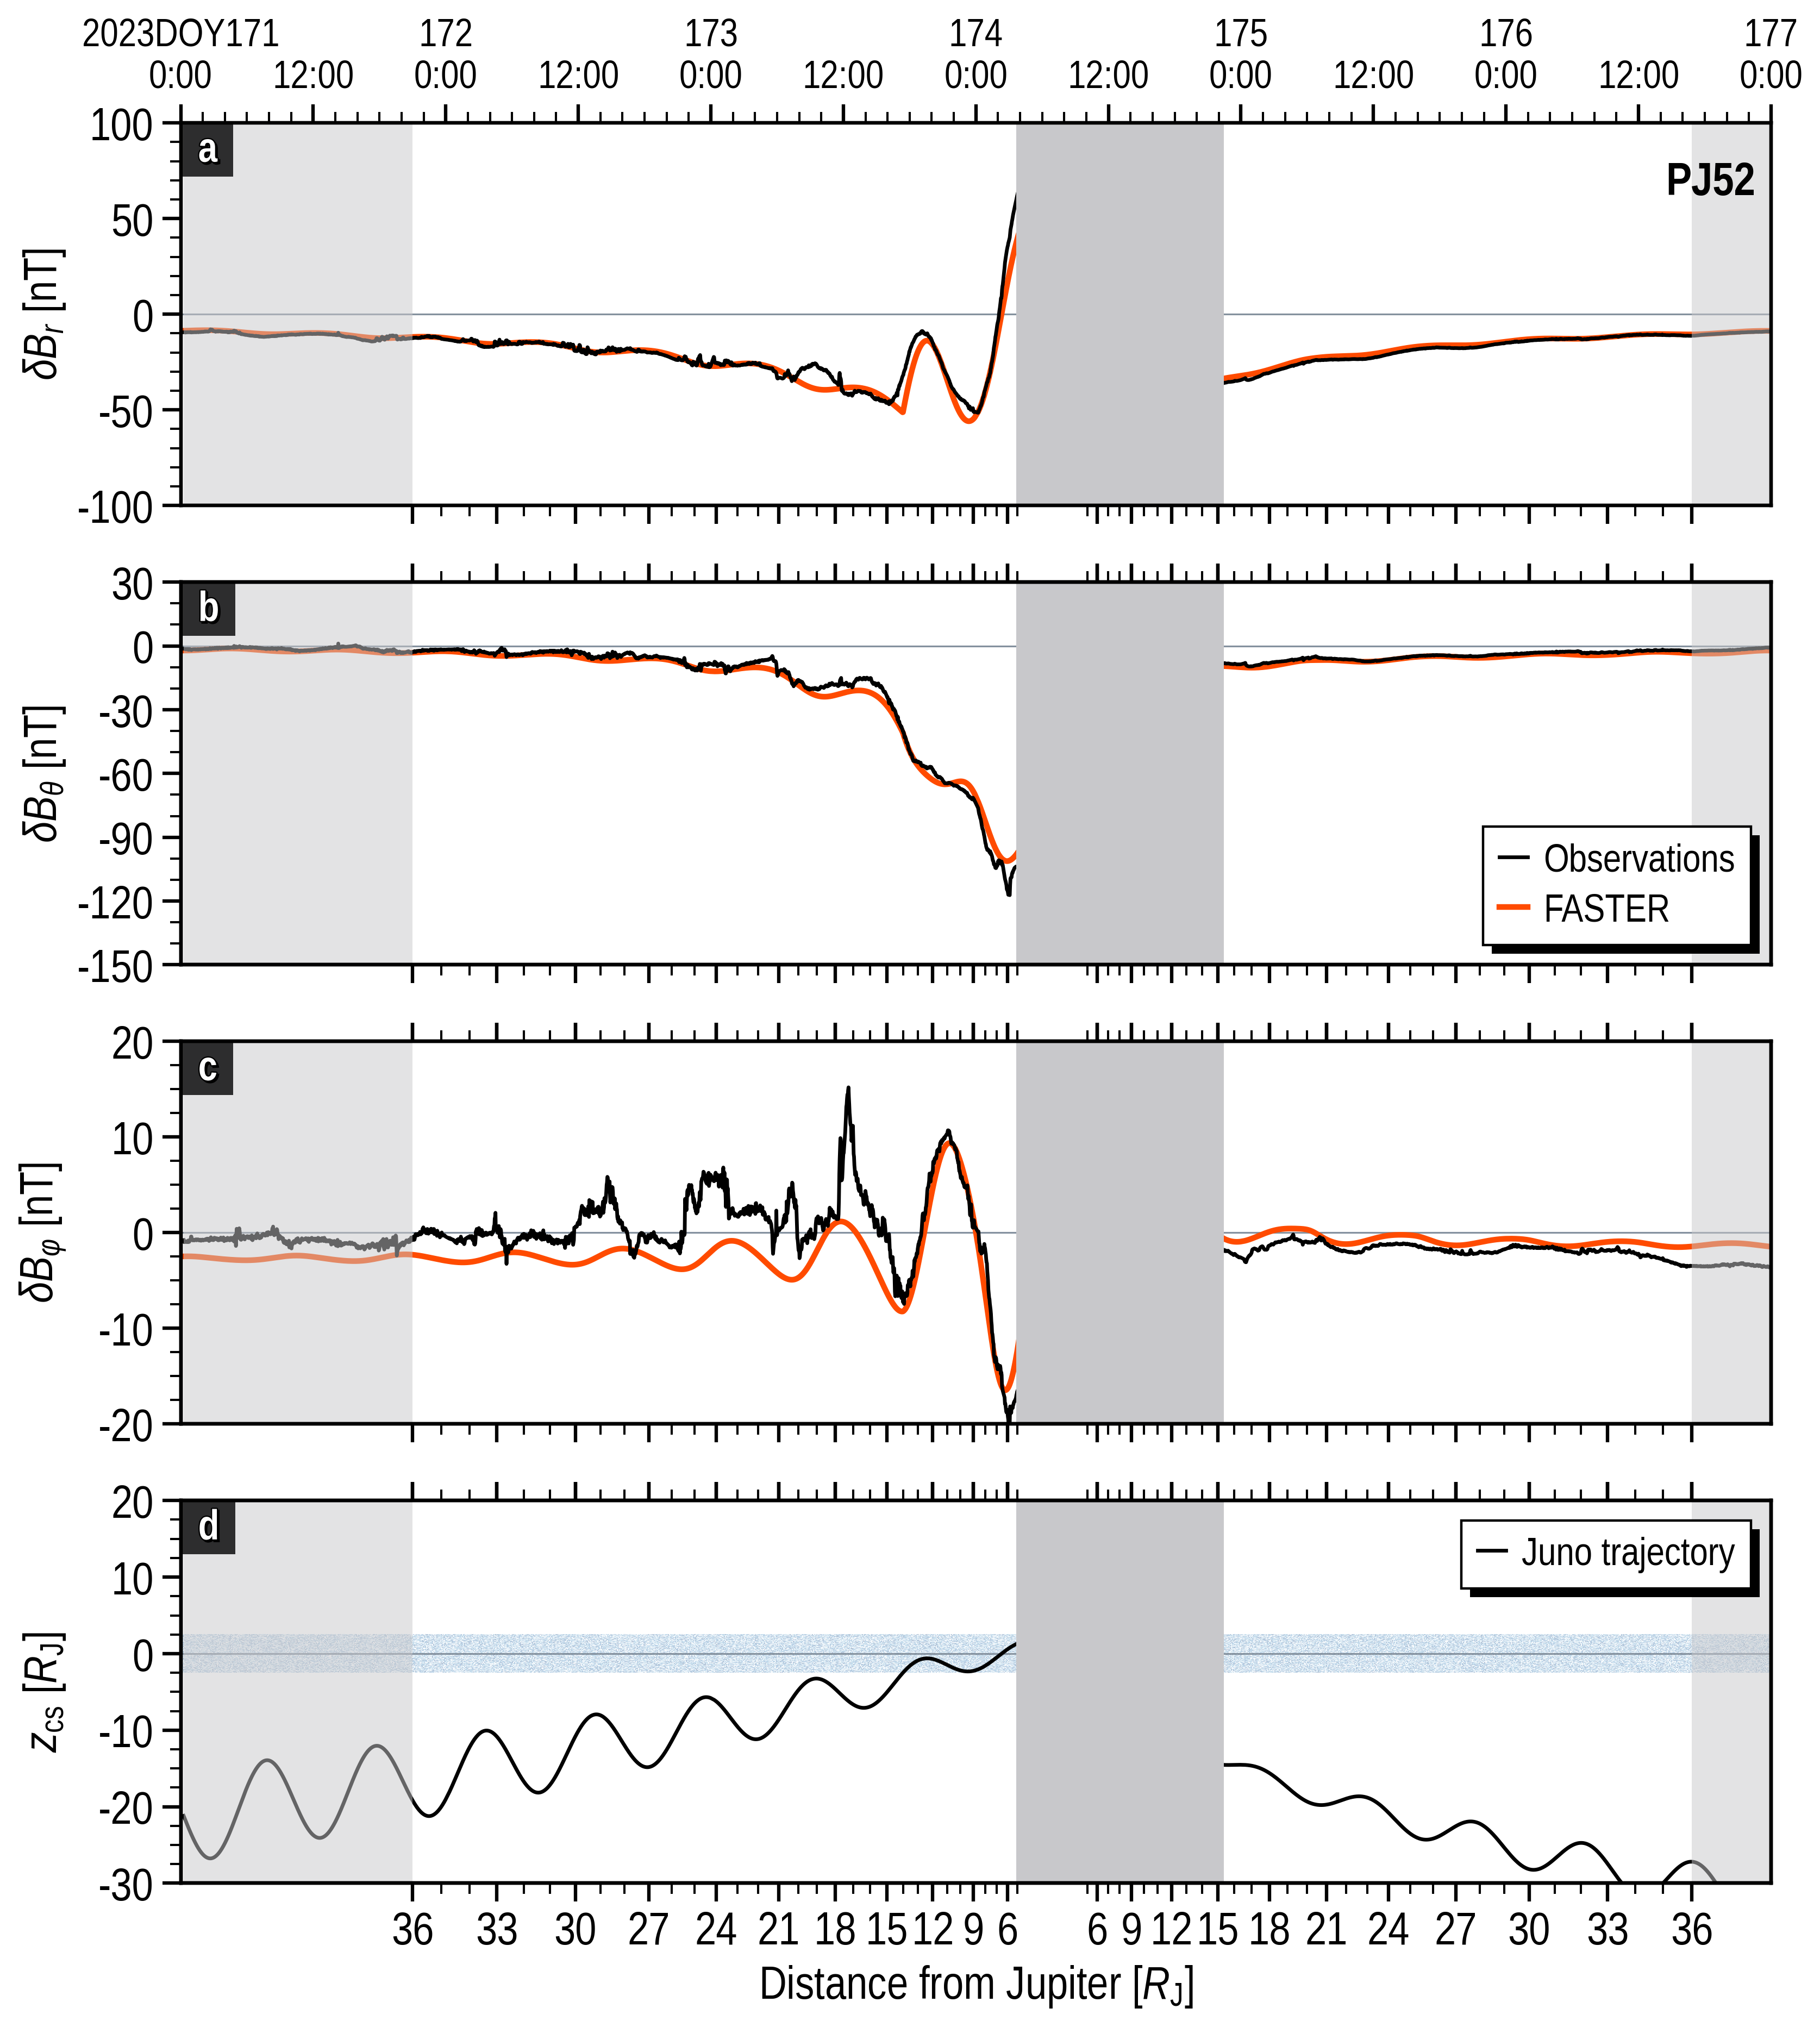

In [105]:
F = ShareXaxis()
F.fontsize = 19
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=4, figsize=(10.0, 11.0), dpi='XL')
F.hspace = 0.2
F.initialize()

xticks = r_ticks[::3, 1]
xticklabels = r_ticks[::3, 0].astype(int)

F.set_xaxis(label=r'Distance from Jupiter [$R_{\rm J}$]',
            min=int(time_arr[0]),
            max=int(time_arr[-1])+1,
            ticks=xticks,
            ticklabels=xticklabels,
            minor_num=None)
for i in range(4):
    F.ax[i].xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
for i in range(3):
    i += 1
    ax_upper = F.ax[i].twiny()
    ax_upper.set_xlim(int(time_arr[0]), int(time_arr[-1])+1)
    ax_upper.set_xticks(xticks)
    ax_upper.xaxis.set_minor_locator(FixedLocator(r_ticks[:, 1]))
    ax_upper.tick_params(labeltop=False)

F.set_yaxis(ax_idx=0,
            label=r'$\delta B_{r}$ [nT]',
            min=-100, max=100,
            ticks=np.linspace(-100, 100, 5),
            ticklabels=np.linspace(-100, 100, 5, dtype=int),
            minor_num=5)
F.set_yaxis(ax_idx=1,
            label=r'$\delta B_{\theta}$ [nT]',
            min=-150, max=30,
            ticks=np.linspace(-150, 30, 7),
            ticklabels=np.linspace(-150, 30, 7, dtype=int),
            minor_num=3)
F.set_yaxis(ax_idx=2,
            label=r'$\delta B_{\varphi}$ [nT]',
            min=-20, max=20,
            ticks=np.linspace(-20, 20, 5),
            ticklabels=np.linspace(-20, 20, 5, dtype=int),
            minor_num=4)
F.set_yaxis(ax_idx=3,
            label=r'$z_{\rm cs}$ [$R_{\rm J}$]',
            min=-30, max=20,
            ticks=np.linspace(-30, 20, 6),
            ticklabels=np.linspace(-30, 20, 6, dtype=int),
            minor_num=4)
F.ax[0].plot(time_arr, dBr, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[0].plot(time_arr, dBr2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[1].plot(time_arr, dBtheta, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[1].plot(time_arr, dBtheta2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[2].plot(time_arr, dBphi, color='k',
             linewidth=1.5, label='Observations', zorder=2.0)
F.ax[2].plot(time_arr, dBphi2_pc, color=UC.red,
             linewidth=2.3, label='FASTER', zorder=1.0)
F.ax[3].plot(time_arr, z_cs, color='k',
             linewidth=1.5, label='Juno trajectory', zorder=1.0)

# z_cs current sheet shade
rng = np.random.default_rng(40)
noise = rng.random((500, 1500))
im = F.ax[3].imshow(
    noise,
    extent=[int(time_arr[0]), int(time_arr[-1])+1, -2.5, 2.5],
    origin="lower",
    cmap="Blues",
    alpha=0.3,
    interpolation="nearest",
    aspect="auto",
)

# Shades near Jupiter (< 5.0 RJ)
inner_idx = np.where((rho_cs < np.min(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[inner_idx[0]],
                    time_arr[inner_idx[-1]],
                    fc=UC.lightgray, ec=None, zorder=2.5)

# Shades in the outer region
outer_idx = np.where((r_pc < np.max(r_ticks_ref)))[0]
for i in range(F.nrows):
    F.ax[i].axvspan(time_arr[0],
                    time_arr[outer_idx[0]],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)
    F.ax[i].axvspan(time_arr[outer_idx[-1]],
                    time_arr[-1],
                    fc=UC.lightgray, alpha=0.5, ec=None, zorder=2.5)

# y = 0 line
for i in range(F.nrows):
    F.ax[i].axhline(y=0.0, color=UC.gray, linewidth=0.7, zorder=0.9)

# Time axis
timeax = F.ax[0].twiny()
timeax.set_xlim(171, 177)
timeax.set_xticks(np.arange(171, 177+0.1, 0.5))
timeax.set_xticklabels([date_list[0]+'\n0:00', '12:00',
                        '172\n0:00', '12:00',
                        '173\n0:00', '12:00', '174\n0:00', '12:00',
                        '175\n0:00', '12:00', '176\n0:00', '12:00',
                        '177\n0:00'], fontsize=F.fontsize*0.85)
timeax.xaxis.set_minor_locator(ptick.AutoMinorLocator(6))

F.ax[0].text(0.99, 0.9, 'PJ'+str(PJ_num).zfill(2),
             color='k',
             fontweight='bold',
             fontsize=F.fontsize,
             verticalalignment='top',
             horizontalalignment='right',
             transform=F.ax[0].transAxes)

legend = F.legend(ax_idx=1,
                  ncol=1, markerscale=1.0,
                  loc='lower right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[1], d=0.7)
legend = F.legend(ax_idx=3,
                  ncol=1, markerscale=1.0,
                  loc='upper right',
                  handlelength=0.72,
                  textcolor=False,
                  fontsize_scale=0.85,
                  handletextpad=0.4)
legend_shadow(legend=legend, fig=F.fig, ax=F.ax[3], d=0.7)

plt.savefig('img/compare_a0_a1_b1_36rj/PJ'+str(PJ_num).zfill(2)+'.pdf',
            bbox_inches='tight')